# Fase 4 — Semana 3
## Visualización y comunicación de resultados
**Pertenencia al SNSS y nivel de complejidad de los establecimientos de salud en Chile**

**Grupo 1:** Brian Cerda · Kattia Espinoza · Karla Martínez · Christopher Ulloa

---

### El proyecto en pocas líneas

En Chile coexisten establecimientos de salud que pertenecen al **Sistema Nacional de Servicios de Salud (SNSS)** y
otros que no forman parte de él (privados, de las Fuerzas Armadas y de Orden, de Gendarmería, entre otros). Cada
establecimiento tiene además un **nivel de complejidad** (baja, mediana o alta), que indica qué tipo de atención puede
resolver y, por lo tanto, a dónde se deriva a un paciente que necesita más de lo que ese establecimiento ofrece. Saber
si la complejidad se distribuye de forma distinta según la pertenencia al SNSS es un antecedente para planificar la red
asistencial, coordinar derivaciones entre el sector público y el privado y asignar recursos.

La pregunta que guía el proyecto desde la Fase 1 es: **¿existe asociación entre la pertenencia al SNSS y el nivel de
complejidad en los establecimientos de salud vigentes, con código único y con ambas variables informadas?** La
población que la responde son los **4.603 establecimientos** que quedaron tras aplicar los criterios de la Fase 2.

### Qué hace esta fase

Este cuaderno cierra el proyecto. No vuelve a limpiar ni a transformar: **recibe las salidas que dejó la Fase 3**,
construye a partir de ellas una copia legible y responde con figuras los objetivos declarados en la Fase 1. También
hace lo que la Fase 1 dejó comprometido para esta etapa: la prueba de independencia, la magnitud de la asociación y su
revisión según el tipo de establecimiento.

| Fase | Cuaderno | Qué entrega a la siguiente |
|---|---|---|
| F1 | `F1/Grupo1_F1_Definicion.ipynb` | Problema, pregunta, objetivos, entorno y ficha del conjunto |
| F2 | `F2/Grupo1_F2_Preprocesamiento.ipynb` | Población de 4.603 establecimientos, decisiones de limpieza y matriz 0/1 |
| F3 | `F3/Grupo1_S2_F3_NucleoAlgoritmico_Eficiencia_POO.ipynb` | El mismo pipeline en clases, con su costo medido, y sus salidas en `data/processed/f3/` |
| **F4** | **este cuaderno** | Figuras, prueba de independencia, hallazgos y evidencia para el informe y el video |

**Cómo usarlo.** Ejecuten antes F1, F2 y F3, en ese orden (o `python ejecutar_proyecto.py`, que corre las cuatro
fases). Este cuaderno se detiene con un mensaje claro si no encuentra las salidas de la Fase 3: no genera datos de
reemplazo, porque una figura hecha con datos inventados no responde ninguna pregunta.

**El principio que ordena la fase.** Una figura responde una pregunta. Si no responde algún objetivo declarado en la
Fase 1, no pertenece al informe; y si un objetivo no tiene evidencia que lo responda, el trabajo está incompleto.

### Conceptos que se usan en esta fase

| Concepto | Qué es | Para qué se usa aquí |
|---|---|---|
| Copia legible | Tabla con las categorías escritas como texto («SNSS», «Mediana»), reconstruida desde la matriz 0/1 | Graficar y comunicar sin modificar las salidas de la Fase 3 |
| Proporción dentro del grupo | Establecimientos de una complejidad divididos por el total de su grupo de pertenencia | Comparar grupos de distinto tamaño (3.065 SNSS y 1.538 No SNSS) |
| Intervalo de Wilson al 95 % | Rango de valores compatibles con una proporción, que no da límites negativos ni mayores que 1 | Mostrar cuán estable es cada proporción según el número de establecimientos que la sostiene |
| Prueba chi-cuadrado de independencia | Compara la tabla observada con la que habría si pertenencia y complejidad no tuvieran relación | Responder si existe asociación |
| V de Cramér | Medida de 0 a 1 de la fuerza de la asociación | Decir cuán fuerte es, más allá de si existe |
| Residuo ajustado | Distancia estandarizada entre lo observado y lo esperado en cada celda | Saber en qué combinaciones se concentra la asociación |
| Variable de confusión | Tercera variable relacionada con las dos que se comparan | Revisar si el tipo de establecimiento o la región explican la asociación |
| Paradoja de Simpson | Una diferencia que cambia de dirección al comparar dentro de subgrupos | Interpretar correctamente la alta complejidad |
| Factor de mentira | Cociente entre el efecto que muestra una figura y el que tienen los datos | Justificar que todas las barras partan en cero |

### Recorrido

| Sección | Contenido |
|---|---|
| 1 | Entorno, ubicación del proyecto y estilo de las figuras |
| 2 | Lo que entregó la Fase 3: contrato, copia legible y verificación contra el archivo original |
| 3 | Objetivos de la Fase 1 y la evidencia que los responde |
| 4 | Figuras 1 a 4: alcance, población, estandarización y distribución |
| 5 | Prueba de independencia y V de Cramér (Figura 5) |
| 6 | La asociación según el tipo de establecimiento (Figuras 6 y 7) y según la región (Figuras 8 y 9) |
| 7 | Una figura que engaña, y cómo corregirla |
| 8 | Eficiencia: reconstruir las categorías (Figura 10) |
| 9 | Validación técnica: casos normales, límite y excepciones |
| 10 | Persistencia: figuras, hallazgos y metadatos |
| 11 | El relato en tres actos, guion del video, limitaciones y pendientes cerrados |
| 12 | Referencias |

---
## 1. Entorno y ubicación del proyecto

La primera comprobación es la misma de las fases anteriores: que el cuaderno corra con el intérprete del entorno
virtual del proyecto y con las versiones declaradas en `requirements.txt`. En esta fase se agrega **SciPy**, que se
usa en un solo lugar (la prueba chi-cuadrado de la sección 5); por eso su versión quedó fijada en el archivo de
dependencias y el cuaderno F1 la comprueba como al resto.

In [1]:
import json
import sys
from datetime import date
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import scipy

SEMILLA = 42
np.random.seed(SEMILLA)

print("Python     :", sys.version.split()[0])
print("Entorno    :", "virtual del proyecto" if sys.prefix != sys.base_prefix else "AVISO: Python del sistema")
print("pandas     :", pd.__version__)
print("NumPy      :", np.__version__)
print("Matplotlib :", matplotlib.__version__)
print("SciPy      :", scipy.__version__)

Python     : 3.13.18
Entorno    : virtual del proyecto
pandas     : 3.0.5
NumPy      : 2.5.2
Matplotlib : 3.11.1
SciPy      : 1.18.1


In [2]:
def localizar_raiz(inicio=None):
    """Devuelve la raíz del proyecto aunque Jupyter abra el kernel en la carpeta F4."""
    actual = Path(inicio or Path.cwd()).resolve()
    return actual.parent if actual.name in {"F1", "F2", "F3", "F4"} else actual


RAIZ = localizar_raiz()
if str(RAIZ) not in sys.path:            # permite importar src/ y tests/ desde la carpeta F4
    sys.path.insert(0, str(RAIZ))

from src import comunicacion as com
from src.configuracion import AGRUPACION_TIPOS, CODIFICACIONES, ORDEN_COMPLEJIDAD, ORDEN_GRUPOS, ORDEN_TIPOS
from src.medicion import medir, tiempo_minimo

PROYECTO = json.loads((RAIZ / "docs/proyecto.json").read_text(encoding="utf-8"))   # definición de la Fase 1
METADATOS_F3 = json.loads((RAIZ / "docs/f3/metadatos_f3.json").read_text(encoding="utf-8"))
RUTA_ORIGINAL = RAIZ / "data/raw" / PROYECTO["fuente"]["archivo"]
DIR_FIGURAS = RAIZ / "F4/figuras"
DIR_DOCS_F4 = RAIZ / "docs/f4"
DIR_DOCS_F4.mkdir(parents=True, exist_ok=True)

# El entorno debe coincidir con requirements.txt, igual que en F1 (aquí solo se informa)
declaradas = dict(linea.split("==") for linea in (RAIZ / "requirements.txt").read_text(encoding="utf-8").split()
                  if "==" in linea)
diferencias = {nombre: (requerida, version(nombre)) for nombre, requerida in declaradas.items()
               if version(nombre) != requerida}
assert not diferencias, f"El entorno no coincide con requirements.txt: {diferencias}"

print("Raíz del proyecto  :", RAIZ.name)
print("Archivo de origen  :", RUTA_ORIGINAL.relative_to(RAIZ).as_posix())
print("Figuras de F4      :", DIR_FIGURAS.relative_to(RAIZ).as_posix())
print("Tablas de F4       :", DIR_DOCS_F4.relative_to(RAIZ).as_posix())
print("Dependencias       :", ", ".join(f"{n}=={v}" for n, v in declaradas.items()))

Raíz del proyecto  : repo
Archivo de origen  : data/raw/establecimientos_20261103.csv
Figuras de F4      : F4/figuras
Tablas de F4       : docs/f4
Dependencias       : pandas==3.0.5, numpy==2.5.2, matplotlib==3.11.1, nbformat==5.11.1, nbclient==0.11.0, ipykernel==7.4.0, scipy==1.18.1


**Qué muestran estas dos celdas.** La primera confirma que el cuaderno corre en el entorno virtual del proyecto y con
las versiones de las bibliotecas que declara `requirements.txt`; si alguna fuera distinta, la segunda celda se
detendría antes de calcular nada, porque un resultado obtenido con otras versiones no sería reproducible. La segunda
ubica la raíz del proyecto aunque Jupyter abra el cuaderno desde la carpeta `F4/`, importa el módulo
`src/comunicacion.py` (la única pieza de código nueva de esta fase) y lee la definición del proyecto que escribió la
Fase 1 (`docs/proyecto.json`): la pregunta, los objetivos, el alcance y los supuestos que aquí se responden y revisan.

### Estilo de las figuras

Se define una sola vez, para que todas las figuras se lean como parte de un mismo documento. El color tiene una
**función**, no es decoración:

- **SNSS en azul y No SNSS en ocre**, en todas las figuras: el mismo grupo conserva su color de principio a fin.
- **El granate señala el hallazgo**: lo que el título afirma está en granate, y el resto queda en grises.
- El color nunca es el único canal: cada barra lleva su etiqueta o su valor escrito, para quien no distingue colores.

Las funciones `pct`, `miles` y `dec` escriben las cifras como en el informe: coma decimal y punto de miles.

In [3]:
AZUL = "#06304A"        # SNSS
OCRE = "#B7791F"        # No SNSS
GRANATE = "#AC212E"     # el hallazgo que la figura quiere mostrar
TINTA = "#0A1526"       # texto
GRIS = "#8A94A0"        # contexto
HIELO = "#D7E3EE"       # fondos y segmentos secundarios
COLOR_GRUPO = {"SNSS": AZUL, "No SNSS": OCRE}

plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (8, 4.4), "font.size": 10,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10.5, "axes.labelcolor": TINTA, "axes.edgecolor": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})
FUENTE = "Fuente: elaboración propia con el registro de establecimientos de salud (DEIS, Minsal), corte 2026-11-03."


def pct(proporcion, decimales=1):
    """Porcentaje con coma decimal: 0,9168 -> «91,7 %»."""
    return f"{proporcion * 100:.{decimales}f} %".replace(".", ",")


def miles(numero):
    """Entero con punto de miles: 4603 -> «4.603»."""
    return f"{int(numero):,}".replace(",", ".")


def dec(numero, decimales=2):
    """Número con coma decimal y punto de miles: 1988.45 -> «1.988,45»."""
    return f"{numero:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def eje_porcentaje(eje):
    """Formatea el eje como porcentaje: el lector no debe convertir proporciones."""
    eje.set_major_formatter(PercentFormatter(1.0, decimals=0))


def nota_fuente(figura, texto=FUENTE, altura=-0.02):
    """Fuente al pie, debajo de la etiqueta del eje x (y de la leyenda, si va abajo) para no taparlas."""
    figura.text(0.01, altura, texto, fontsize=8, color=GRIS, ha="left", va="top", wrap=True)

---
## 2. Lo que entregó la Fase 3

### 2.1 Carga de las salidas

`cargar_artefactos` vive en `src/comunicacion.py`. Lee las cinco tablas de `data/processed/f3/` y dos registros de
`docs/f3/` (los parámetros que aprendió cada paso y los registros excluidos). Si falta alguno, se detiene y dice qué
cuaderno ejecutar: no hay alternativa silenciosa.

In [4]:
artefactos = com.cargar_artefactos(RAIZ)
for nombre, tabla in artefactos.items():
    print(f"{nombre:<13} {tabla.shape[0]:>5} filas x {tabla.shape[1]:>2} columnas   {com.ARTEFACTOS_F3[nombre]}")

poblacion      4603 filas x  5 columnas   data/processed/f3/poblacion_f3.csv
matriz         4603 filas x  5 columnas   data/processed/f3/matriz_f3.csv
clave_filas    4603 filas x  3 columnas   data/processed/f3/clave_filas_f3.csv
contingencia      2 filas x  3 columnas   data/processed/f3/contingencia_f3.csv
porcentajes       2 filas x  3 columnas   data/processed/f3/porcentajes_f3.csv
parametros       19 filas x  4 columnas   docs/f3/parametros_f3.csv
exclusiones    1234 filas x  7 columnas   docs/f3/exclusiones_f3.csv


**Qué contiene cada archivo y para qué lo usa esta fase.**

| Archivo | Contenido | Uso en F4 |
|---|---|---|
| `poblacion_f3.csv` | Los 4.603 establecimientos con su código, estado, pertenencia y complejidad | Referencia para comprobar la copia legible |
| `matriz_f3.csv` | La misma población codificada en cinco columnas 0/1 (dos de pertenencia y tres de complejidad) | Punto de partida de la copia legible |
| `clave_filas_f3.csv` | Para cada fila de la matriz, su número de línea en el archivo original | Unir cada establecimiento con su tipo y su región |
| `contingencia_f3.csv` | Tabla 2 × 3 de pertenencia por complejidad | Prueba de independencia |
| `porcentajes_f3.csv` | La misma tabla en porcentajes por fila | Comprobar la Figura 4 |
| `parametros_f3.csv` | Lo que aprendió cada paso del pipeline (categorías observadas, columnas generadas, registros evaluados) | Verificar que la codificación coincide con la configuración |
| `exclusiones_f3.csv` | Los 1.234 registros excluidos, con el paso que los excluyó | Desglosar las exclusiones por grupo (Figura 2) |

### 2.2 Verificar el contrato antes de usarlo

La Fase 3 prometió un resultado concreto. Antes de graficar se comprueba que lo cumplió: la matriz tiene las cinco
columnas declaradas, solo contiene 0 y 1 y cada fila tiene exactamente una categoría activa por variable; población,
matriz y clave de filas tienen el mismo largo que registró la Fase 3; la tabla de contingencia suma la población y los
porcentajes de cada grupo suman 100. Las columnas que generó el codificador también deben coincidir con la
configuración: si alguien cambiara el orden en `src/configuracion.py`, aquí se detectaría.

In [5]:
poblacion = artefactos["poblacion"]
matriz = artefactos["matriz"]
contingencia = artefactos["contingencia"]
porcentajes = artefactos["porcentajes"]
parametros = com.leer_parametros(artefactos["parametros"])
COLUMNAS_MATRIZ = [columna for _, mapa in CODIFICACIONES for columna in mapa.values()]
N = METADATOS_F3["filas_poblacion"]

assert list(matriz.columns) == COLUMNAS_MATRIZ == METADATOS_F3["columnas_matriz"], "Columnas de la matriz distintas"
assert matriz.isin([0, 1]).all().all(), "La matriz contiene valores distintos de 0 y 1"
for variable, mapa in CODIFICACIONES:
    assert (matriz[list(mapa.values())].sum(axis=1) == 1).all(), f"{variable}: filas sin una sola categoría"
    assert parametros[f"CodificadorBinario({variable})"]["columnas_generadas"] == list(mapa.values())
assert len(poblacion) == len(matriz) == len(artefactos["clave_filas"]) == N, "Largos distintos entre salidas"
assert poblacion.notna().all().all(), "La población tiene valores faltantes"
assert int(contingencia.to_numpy().sum()) == N, "La contingencia no suma la población"
assert list(contingencia.index) == ORDEN_GRUPOS and list(contingencia.columns) == ORDEN_COMPLEJIDAD
assert np.allclose(porcentajes.sum(axis=1), 100), "Los porcentajes de cada grupo no suman 100"
assert METADATOS_F3["identico_a_f2"], "La Fase 3 no reprodujo los resultados de la Fase 2"

print("Contrato de la Fase 3: cumplido")
print(f"Población: {miles(N)} establecimientos · matriz {matriz.shape[0]} x {matriz.shape[1]}")
print(f"Pasos con parámetros registrados: {len(parametros)}")

Contrato de la Fase 3: cumplido
Población: 4.603 establecimientos · matriz 4603 x 5
Pasos con parámetros registrados: 19


**Qué garantiza este contrato.** Si alguna de estas condiciones fallara, las figuras se construirían sobre datos
distintos de los que describió la Fase 3 y el informe afirmaría cifras que el repositorio no respalda. Las más
importantes para este proyecto son tres: que la matriz tenga exactamente una pertenencia y una complejidad por
establecimiento (si no, un establecimiento se contaría dos veces o ninguna), que la tabla de contingencia sume 4.603
(el denominador de todas las proporciones) y que la Fase 3 haya reproducido de forma idéntica los resultados de la
Fase 2, que es lo que permite decir que las cuatro fases describen la misma población.

### 2.3 La copia legible

La matriz 0/1 sirve para calcular, pero no para comunicar: una barra sobre la columna `complejidad_mediana` no le dice
nada a quien lee el informe. Para graficar se construye una **copia** con las categorías como texto, y se dejan intactas
las salidas de la Fase 3.

En este proyecto la copia es más simple que en un caso con variables continuas. **No hay escalamiento que revertir**:
las dos variables son categóricas y la Fase 3 no las escaló (sus indicadores ya están en 0 y 1). Lo único que hay que
deshacer es la codificación One-Hot, y eso hace `reconstruir_categorias`:

- Usa el **vocabulario de la Fase 3** (`CODIFICACIONES`), no las columnas que encuentre. Una categoría inesperada
  detiene la ejecución en vez de pasar inadvertida.
- Une cada columna con su categoría **por nombre y no por posición**. En los parámetros, las categorías aparecen en
  orden alfabético (`No SNSS`, `SNSS`) y las columnas en el orden de la matriz (`snss_perteneciente`,
  `snss_no_perteneciente`): unirlas por posición intercambiaría los grupos sin dar ningún error.

La clave de filas agrega a cada fila su número de línea en el archivo original, que se usa en 2.4 y en la sección 6.

In [6]:
legible = com.copia_interpretable(artefactos, CODIFICACIONES, parametros)
print(f"Copia legible: {legible.shape[0]} filas x {legible.shape[1]} columnas")
print("Matriz de la Fase 3 sin modificar:", artefactos["matriz"].equals(matriz))
legible.head()

Copia legible: 4603 filas x 4 columnas
Matriz de la Fase 3 sin modificar: True


,fila_origen,codigo_establecimiento,pertenencia_snss,complejidad
0,2,101011,SNSS,Baja
1,3,200601,SNSS,Mediana
2,4,101608,SNSS,Mediana
3,5,101012,SNSS,Baja
4,6,101607,SNSS,Mediana


**Cómo leer la copia.** Cada fila es un establecimiento de la población. `fila_origen` es su número de línea en el
archivo descargado del DEIS (la línea 1 es el encabezado), `codigo_establecimiento` es su código vigente, y
`pertenencia_snss` y `complejidad` son las dos variables del estudio, ya en texto. Desde aquí, toda la fase trabaja con
esta tabla: es la que se cruza con el tipo de establecimiento y la región, y la que se resume en cada figura.

### 2.4 La verificación que más rinde: contra el archivo original

Comprobar la copia con el mismo código que la produjo sería circular. Por eso se compara con dos fuentes que **no
pasan por `src/`**:

1. **El archivo original de `data/raw`**, leído aquí directamente con pandas. Cada fila de la copia se ubica en el
   archivo por su número de línea, y su código y sus dos categorías deben coincidir con lo que dice el registro. La
   traducción de las glosas se escribe de nuevo en esta celda, a mano, sin usar la configuración.
2. **La tabla de contingencia de la Fase 2**, que se calculó antes de que existieran las clases de la Fase 3.

Si la copia, la Fase 3 y la Fase 2 coinciden, las tres fases cuentan exactamente los mismos establecimientos.

In [7]:
import hashlib

if not RUTA_ORIGINAL.is_file():
    raise FileNotFoundError(f"No se encontró el archivo de origen: {RUTA_ORIGINAL.relative_to(RAIZ).as_posix()}. "
                            "No se versiona: el README explica cómo descargarlo, y verificar_fuente.py lo comprueba.")
huella = hashlib.sha256(RUTA_ORIGINAL.read_bytes()).hexdigest()

original = pd.read_csv(RUTA_ORIGINAL, sep=";", dtype=str, keep_default_na=False)
original.insert(0, "fila_origen", np.arange(2, len(original) + 2))     # línea 1: encabezado

cruce = legible.merge(original, on="fila_origen", how="left", validate="one_to_one")
texto = lambda serie: serie.str.strip().str.lower()
pertenencia_original = texto(cruce["TipoPertenenciaEstabGlosa"]).map({
    "perteneciente al sistema nacional de servicios de salud": "SNSS",
    "no perteneciente al sistema nacional de servicios de salud": "No SNSS"})
complejidad_original = texto(cruce["NivelComplejidadEstabGlosa"]).map({
    "baja complejidad": "Baja", "mediana complejidad": "Mediana", "alta complejidad": "Alta"})

contingencia_f2 = pd.read_csv(RAIZ / "data/processed/tabla_contingencia.csv", encoding="utf-8-sig", index_col=0)
contingencia_copia = pd.crosstab(legible["pertenencia_snss"], legible["complejidad"])

comprobaciones = {
    "Huella SHA-256 del archivo = la registrada en F1 y F3": huella == METADATOS_F3["sha256_original"],
    "Mismo número de establecimientos que la Fase 3": len(legible) == N,
    "Cada fila existe en el archivo original": cruce["EstablecimientoCodigo"].ne("").all(),
    "Mismo código que en el archivo original": (cruce["codigo_establecimiento"]
                                                == cruce["EstablecimientoCodigo"].str.strip()).all(),
    "Misma pertenencia que en el archivo original": (pertenencia_original == cruce["pertenencia_snss"].astype(str)).all(),
    "Misma complejidad que en el archivo original": (complejidad_original == cruce["complejidad"].astype(str)).all(),
    "Sin códigos repetidos": legible["codigo_establecimiento"].is_unique,
    "Contingencia de la copia = Fase 3": np.array_equal(contingencia_copia.to_numpy(), contingencia.to_numpy()),
    "Contingencia de la copia = Fase 2": np.array_equal(contingencia_copia.to_numpy(), contingencia_f2.to_numpy()),
}
for control, resultado in comprobaciones.items():
    print(f"[{'OK' if resultado else 'FALLA'}] {control}")
assert all(comprobaciones.values()), "La copia legible no coincide con el archivo original o con las fases previas"
contingencia_copia

[OK] Huella SHA-256 del archivo = la registrada en F1 y F3
[OK] Mismo número de establecimientos que la Fase 3
[OK] Cada fila existe en el archivo original
[OK] Mismo código que en el archivo original
[OK] Misma pertenencia que en el archivo original
[OK] Misma complejidad que en el archivo original
[OK] Sin códigos repetidos
[OK] Contingencia de la copia = Fase 3
[OK] Contingencia de la copia = Fase 2


complejidad,Baja,Mediana,Alta
pertenencia_snss,,,
SNSS,2810,183,72
No SNSS,460,1023,55


**Qué demuestra este resultado.** Las nueve comprobaciones son correctas: el archivo de origen es exactamente la versión
que usaron las fases anteriores (misma huella SHA-256), cada uno de los 4.603 establecimientos existe en él con el
mismo código, la misma pertenencia y la misma complejidad, y la tabla de contingencia es idéntica en la copia, en la
Fase 3 y en la Fase 2. En otras palabras, la reconstrucción no introdujo ningún error, y las cifras de este cuaderno
son las mismas que sostienen el informe de las fases anteriores.

---
## 3. Los objetivos de la Fase 1 y la figura que responde cada uno

La Fase 1 declaró una pregunta y seis objetivos específicos. Antes de graficar se fija, para cada objetivo, la pregunta
concreta que se deriva de él, la figura que la responde y el tipo de gráfico, elegido según **lo que se compara** y no
según el gusto: una proporción entre grupos va en barras; una composición, en barras apiladas al 100 %; una tabla
cruzada con su desviación de la independencia, en un mapa de calor; una comparación dentro de estratos, en paneles con
la misma escala; la variación de una proporción entre muchos subgrupos, en cajas con sus puntos; la relación entre dos
proporciones medidas en las mismas unidades, en una dispersión; y un crecimiento, en líneas.

Todos los objetivos tienen al menos una figura. Los que tratan del proceso (delimitar, estandarizar, reorganizar el
código) también tienen controles y mediciones que los respaldan, indicados en la última columna.

In [8]:
print("Pregunta:", PROYECTO["pregunta"], "\n")
plan = [
    ("¿Cuántos registros cumplen el alcance, y qué criterio excluye más?",
     "Figura 1", "Barras horizontales por paso", "Contrato y verificación contra el archivo (sección 2)"),
    ("¿Los criterios de inclusión excluyen por igual a SNSS y No SNSS?",
     "Figura 2", "Barras apiladas al 100 %", "Registro de exclusiones de F3"),
    ("¿Qué habría pasado sin unificar las categorías escritas de distinta forma?",
     "Figura 3", "Barras por grupo y complejidad", "Copia legible verificada contra el archivo original (2.4)"),
    ("¿Cómo se distribuye la complejidad dentro de cada grupo?",
     "Figura 4", "Barras agrupadas con intervalo", "Porcentajes de F3"),
    ("¿Cuánto cuesta reconstruir las categorías y cómo crece con el volumen?",
     "Figura 10", "Líneas en escala logarítmica", "Mediciones con timeit y tracemalloc (sección 8)"),
    ("¿Existe asociación, y se mantiene al comparar el mismo tipo de establecimiento?",
     "Figuras 5 a 9", "Mapa de calor; barras apiladas; paneles; caja con puntos; dispersión",
     "Prueba chi-cuadrado y V de Cramér dentro de los 5 tipos compartidos y por región"),
]
vinculacion = pd.DataFrame({
    "objetivo": [f"{i}. {texto.split(' (Fase')[0]}" for i, texto in enumerate(PROYECTO["objetivos_especificos"], 1)],
    "pregunta": [p[0] for p in plan],
    "figura": [p[1] for p in plan],
    "grafico": [p[2] for p in plan],
    "evidencia complementaria": [p[3] for p in plan],
})
assert len(vinculacion) == len(PROYECTO["objetivos_especificos"]), "Hay objetivos sin figura asignada"
assert vinculacion["figura"].str.startswith("Figura").all(), "Todo objetivo debe tener al menos una figura"
with pd.option_context("display.max_colwidth", 70):
    display(vinculacion)

Pregunta: ¿Existe asociación entre la pertenencia al SNSS y el nivel de complejidad en los establecimientos de salud vigentes con código único y con ambas variables informadas en la base? 



,objetivo,pregunta,figura,grafico,evidencia complementaria
0,"1. Delimitar el problema de investigación, la pregunta, el alcance...","¿Cuántos registros cumplen el alcance, y qué criterio excluye más?",Figura 1,Barras horizontales por paso,Contrato y verificación contra el archivo (sección 2)
1,2. Definir la población de análisis mediante criterios explícitos ...,¿Los criterios de inclusión excluyen por igual a SNSS y No SNSS?,Figura 2,Barras apiladas al 100 %,Registro de exclusiones de F3
2,3. Estandarizar las categorías de pertenencia al SNSS y de nivel d...,¿Qué habría pasado sin unificar las categorías escritas de distint...,Figura 3,Barras por grupo y complejidad,Copia legible verificada contra el archivo original (2.4)
3,4. Describir la distribución de los establecimientos según su pert...,¿Cómo se distribuye la complejidad dentro de cada grupo?,Figura 4,Barras agrupadas con intervalo,Porcentajes de F3
4,5. Reorganizar el flujo de F1 y F2 en un diseño modular orientado ...,¿Cuánto cuesta reconstruir las categorías y cómo crece con el volu...,Figura 10,Líneas en escala logarítmica,Mediciones con timeit y tracemalloc (sección 8)
5,6. Evaluar la asociación entre ambas variables mediante una tabla ...,"¿Existe asociación, y se mantiene al comparar el mismo tipo de est...",Figuras 5 a 9,Mapa de calor; barras apiladas; paneles; caja con puntos; dispersión,Prueba chi-cuadrado y V de Cramér dentro de los 5 tipos compartido...


**Cómo se ordenan las figuras.** No siguen el orden de los objetivos sino el del argumento: primero se delimita a quién
se refieren las cifras (Figuras 1 a 3), después se describe la distribución (Figura 4), luego se mide la asociación
(Figura 5) y al final se revisa si se mantiene al comparar establecimientos del mismo tipo y de la misma región
(Figuras 6 a 9). La Figura 10 responde un objetivo de proceso, la eficiencia del código, y por eso aparece en la
sección de medición.

---
## 4. Alcance, población, estandarización y distribución

### Figura 1 · Del archivo a la población de análisis

El alcance que fijó la Fase 1 (establecimientos vigentes, con código único, pertenencia clasificable y complejidad
baja, mediana o alta) se aplica en ocho pasos explícitos, F01 a F08. La figura muestra cuántos registros siguen en la
población después de cada uno. Los pasos que no excluyen nada también se muestran: son comprobaciones (código
informado, sin filas repetidas, sin códigos en conflicto) cuyo resultado es parte de la delimitación.

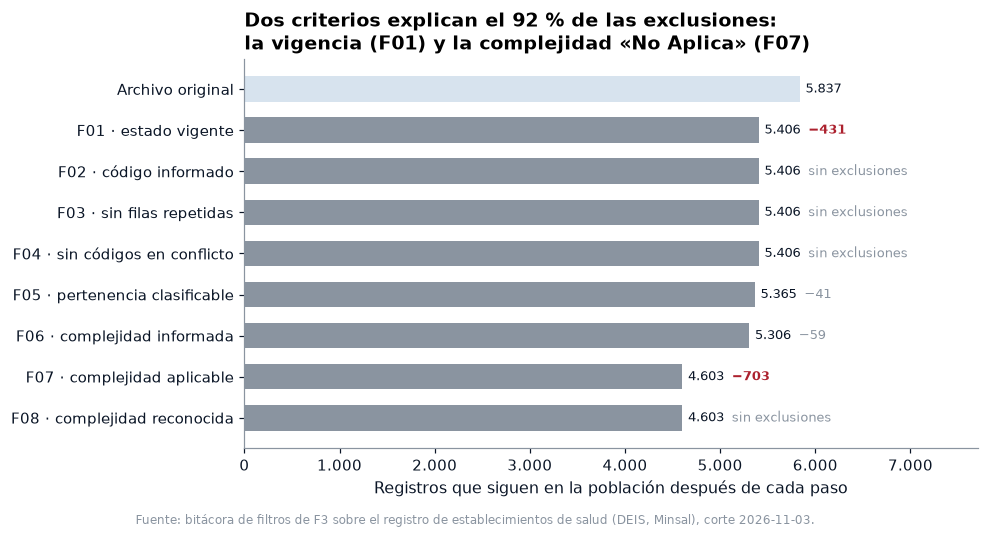

,paso,regla,antes,excluidos,restantes
0,F01,Conservar estado vigente,5837,431,5406
1,F02,Código informado,5406,0,5406
2,F03,Una copia de filas exactamente repetidas,5406,0,5406
3,F04,Excluir códigos con registros distintos en con...,5406,0,5406
4,F05,"Pertenencia clasificable: excluir No Aplica, v...",5406,41,5365
5,F06,Complejidad informada: excluir vacíos,5365,59,5306
6,F07,Complejidad aplicable: excluir No Aplica,5306,703,4603
7,F08,"Complejidad reconocida: Baja, Mediana o Alta",4603,0,4603


In [9]:
filtros = pd.read_csv(RAIZ / "docs/f3/bitacora_filtros_f3.csv", encoding="utf-8-sig")
assert (filtros["antes"] - filtros["excluidos"] == filtros["restantes"]).all(), "La bitácora no es consistente"
assert filtros["antes"].iloc[0] == len(original) and filtros["restantes"].iloc[-1] == N
principales = filtros.nlargest(2, "excluidos")
proporcion_principales = principales["excluidos"].sum() / filtros["excluidos"].sum()
assert set(principales["paso"]) == {"F01", "F07"} and 0.90 <= proporcion_principales < 0.95

NOMBRE_PASO = {"F01": "estado vigente", "F02": "código informado", "F03": "sin filas repetidas",
               "F04": "sin códigos en conflicto", "F05": "pertenencia clasificable",
               "F06": "complejidad informada", "F07": "complejidad aplicable", "F08": "complejidad reconocida"}
etiquetas = ["Archivo original"] + [f"{paso} · {NOMBRE_PASO[paso]}" for paso in filtros["paso"]]
restantes = [int(filtros["antes"].iloc[0])] + filtros["restantes"].astype(int).tolist()
excluidos = [None] + filtros["excluidos"].astype(int).tolist()

fig, ax = plt.subplots(figsize=(8.6, 4.6))
y = np.arange(len(etiquetas))[::-1]
ax.barh(y, restantes, color=[HIELO] + [GRIS] * len(filtros), height=0.62)
for yi, total, menos, paso in zip(y, restantes, excluidos, [None] + filtros["paso"].tolist()):
    ax.text(total + 60, yi, miles(total), va="center", fontsize=8.8, color=TINTA)
    if menos is not None:
        destacado = paso in ("F01", "F07")
        ax.text(total + 520, yi, f"−{miles(menos)}" if menos else "sin exclusiones", va="center", fontsize=8.8,
                color=GRANATE if destacado else GRIS, fontweight="bold" if destacado else "normal")
ax.set_yticks(y, etiquetas)
ax.set_xlim(0, restantes[0] * 1.32)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: miles(v)))
ax.set_xlabel("Registros que siguen en la población después de cada paso")
ax.set_title("Dos criterios explican el 92 % de las exclusiones:\nla vigencia (F01) y la complejidad «No Aplica» (F07)")
nota_fuente(fig, FUENTE.replace("Fuente: elaboración propia con", "Fuente: bitácora de filtros de F3 sobre"))
figuras = {"fig1_alcance_poblacion": fig}
plt.show()

filtros

**Lectura.**

- **Qué muestra.** De los 5.837 registros del archivo quedan 4.603 establecimientos. Se excluyen 1.234: 431 por no
  estar vigentes (F01), 41 por pertenencia no clasificable (F05), 59 por complejidad vacía (F06) y 703 por complejidad
  «No Aplica» (F07). Los pasos F02, F03, F04 y F08 no excluyen nada.
- **Qué se infiere.** El alcance queda delimitado sobre todo por dos criterios, F01 y F07, que reúnen el 92 % de las
  exclusiones. Que F02 a F04 no excluyan nada confirma un supuesto de la Fase 1: cada código vigente identifica un
  único establecimiento.
- **Qué límite tiene.** La figura muestra cuántos registros se excluyen, no a quiénes. Si las exclusiones no afectan
  por igual a los grupos, la población no representa del mismo modo a SNSS y No SNSS; eso lo responde la Figura 2.
- **Cómo aporta al relato.** Fija el denominador de todas las cifras siguientes: 4.603 establecimientos.

### Figura 2 · Dónde se pierden los establecimientos No SNSS

En la Fase 2 la retención fue muy distinta entre grupos (99,0 % de los SNSS vigentes frente a 67,8 % de los No SNSS),
y el desglose por filtro quedó pendiente. Aquí se reconstruye con el registro de exclusiones de la Fase 3: cada
registro del archivo con pertenencia clasificable termina incluido o excluido en un paso concreto. Los 41 registros sin
pertenencia clasificable (F05) no pertenecen a ningún grupo y no se muestran.

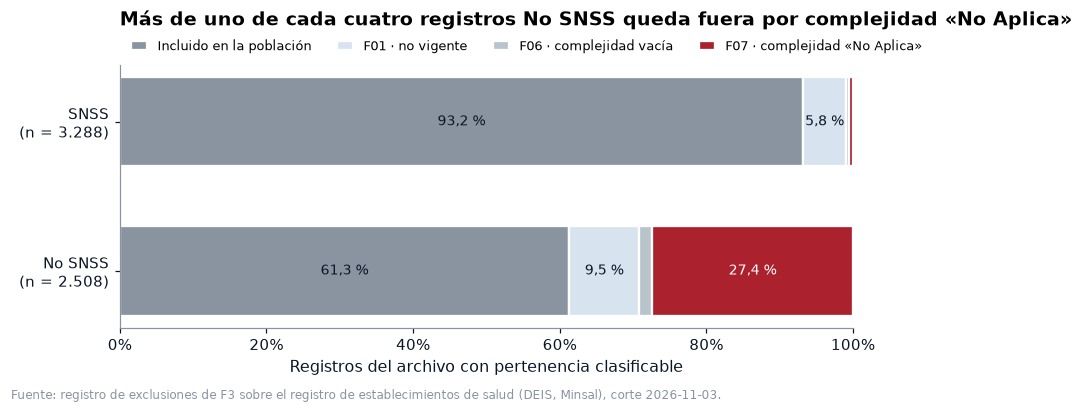

destino,Incluido,F01,F06,F07
grupo,,,,
SNSS,3065,192,14,17
No SNSS,1538,239,45,686


In [10]:
exclusiones = artefactos["exclusiones"].copy()
exclusiones["grupo"] = texto(exclusiones["TipoPertenenciaEstabGlosa"]).map({
    "perteneciente al sistema nacional de servicios de salud": "SNSS",
    "no perteneciente al sistema nacional de servicios de salud": "No SNSS"})
destino = pd.concat([
    pd.DataFrame({"grupo": legible["pertenencia_snss"].astype(str), "destino": "Incluido"}),
    exclusiones.dropna(subset=["grupo"]).rename(columns={"paso_exclusion": "destino"})[["grupo", "destino"]],
], ignore_index=True)
ETIQUETAS_DESTINO = {"Incluido": "Incluido en la población", "F01": "F01 · no vigente",
                     "F06": "F06 · complejidad vacía", "F07": "F07 · complejidad «No Aplica»"}
conteo_destino = pd.crosstab(destino["grupo"], destino["destino"]).loc[ORDEN_GRUPOS, list(ETIQUETAS_DESTINO)]
composicion_destino = conteo_destino.div(conteo_destino.sum(axis=1), axis=0)

# El título se comprueba con los datos: si el resultado cambiara, la celda se detendría
f07_no_snss = composicion_destino.loc["No SNSS", "F07"]
assert 0.25 <= f07_no_snss < 0.30 and composicion_destino.loc["SNSS", "F07"] < 0.01
assert int(conteo_destino["Incluido"].sum()) == N and int(conteo_destino.to_numpy().sum()) == len(original) - 41

COLOR_DESTINO = {"Incluido": GRIS, "F01": HIELO, "F06": "#B9C3CC", "F07": GRANATE}
fig, ax = plt.subplots(figsize=(8.6, 3.1))
for fila, grupo in enumerate(reversed(ORDEN_GRUPOS)):
    izquierda = 0.0
    for destino_paso, etiqueta in ETIQUETAS_DESTINO.items():
        valor = composicion_destino.loc[grupo, destino_paso]
        ax.barh(fila, valor, left=izquierda, color=COLOR_DESTINO[destino_paso], height=0.6,
                label=etiqueta if fila == 0 else None, edgecolor="white", linewidth=1.5)
        if valor >= 0.04:
            color_texto = "white" if destino_paso in ("F07",) else TINTA
            ax.text(izquierda + valor / 2, fila, pct(valor, 1), ha="center", va="center", fontsize=9, color=color_texto)
        izquierda += valor
ax.set_yticks([0, 1], [f"{g}\n(n = {miles(conteo_destino.loc[g].sum())})" for g in reversed(ORDEN_GRUPOS)])
eje_porcentaje(ax.xaxis)
ax.set_xlim(0, 1)
ax.set_xlabel("Registros del archivo con pertenencia clasificable")
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8.5, handlelength=1.2)
ax.set_title("Más de uno de cada cuatro registros No SNSS queda fuera por complejidad «No Aplica»", pad=26)
nota_fuente(fig, FUENTE.replace("Fuente: elaboración propia con", "Fuente: registro de exclusiones de F3 sobre"), altura=-0.07)
figuras["fig2_exclusiones_por_grupo"] = fig
plt.show()

conteo_destino

**Lectura.**

- **Qué muestra.** De los 2.508 registros No SNSS, 686 (27,4 %) se excluyeron porque su complejidad figura como «No
  Aplica»; entre los 3.288 SNSS, solo 17 (0,5 %). La exclusión por no estar vigente (F01) pesa parecido en ambos grupos
  (9,5 % y 5,8 %).
- **Qué se infiere.** La diferencia de retención que observó la Fase 2 no viene de la vigencia, sino casi entera del
  filtro F07: el registro asigna «No Aplica» sobre todo a establecimientos No SNSS.
- **Qué límite tiene.** El estudio no puede saber qué complejidad tendrían esos 686 establecimientos. Si fueran, por
  ejemplo, mayoritariamente de baja complejidad, la distribución No SNSS de la Figura 4 cambiaría. Las conclusiones se
  limitan, como declaró la Fase 1, a los establecimientos con complejidad baja, mediana o alta.
- **Cómo aporta al relato.** Delimita a quién se refieren todas las figuras siguientes, y explica por qué el grupo No
  SNSS es más pequeño en la población que en el archivo.

### Figura 3 · Lo que habría pasado sin estandarizar las categorías

El registro escribe algunas categorías de dos formas que solo difieren en mayúsculas: «Vigente en Operación Habitual» y
«Vigente en operación habitual», o «No Perteneciente…» y «No perteneciente…». La Fase 2 normalizó el texto antes de
aplicar los filtros y de traducir a categorías analíticas. Para medir el efecto de esa decisión, se cuenta cuántos
establecimientos de la población llegaron escritos con la forma minoritaria: con una comparación exacta de texto,
habrían quedado fuera (F01 no los reconocería como vigentes o F05 no reconocería su pertenencia).

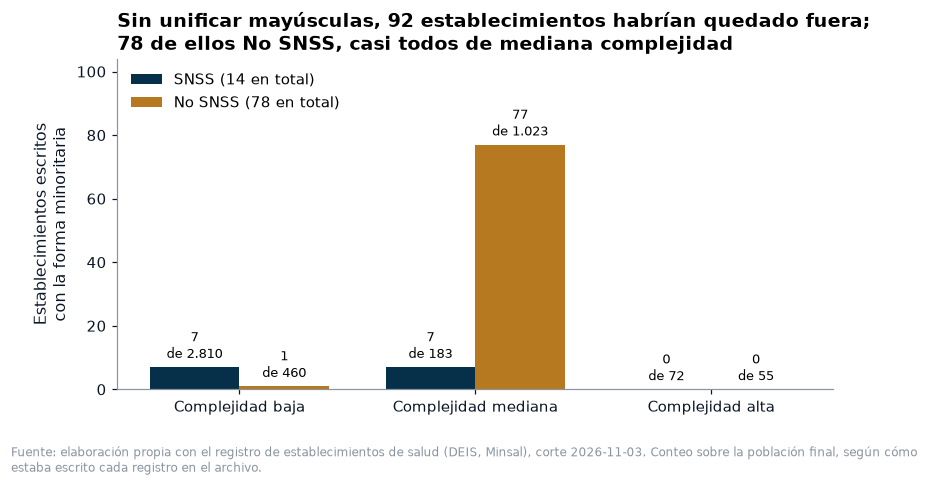

Mediana complejidad entre los No SNSS: 66,5 % con la estandarización, 64,8 % sin ella


,columna,forma mayoritaria,n mayoritaria,forma minoritaria,n minoritaria
0,EstadoFuncionamiento,Vigente en Operación Habitual,4528,Vigente en operación habitual,75
1,TipoPertenenciaEstabGlosa,No Perteneciente al Sistema Nacional de Servic...,1462,No perteneciente al Sistema Nacional de Servic...,76


In [11]:
# Para cada variable del archivo, las formas escritas que se vuelven iguales al normalizar el texto
COLUMNAS_TEXTO = ["EstadoFuncionamiento", "TipoPertenenciaEstabGlosa", "NivelComplejidadEstabGlosa"]
variantes = []
otra_escritura = pd.Series(False, index=cruce.index)
for columna in COLUMNAS_TEXTO:
    for normalizada, sub in cruce.groupby(texto(cruce[columna])):
        formas = sub[columna].value_counts()
        if len(formas) > 1:
            minoritarias = formas.index[1:]
            otra_escritura |= cruce[columna].isin(minoritarias) & (texto(cruce[columna]) == normalizada)
            variantes.append({"columna": columna, "forma mayoritaria": formas.index[0], "n mayoritaria": formas.iloc[0],
                              "forma minoritaria": ", ".join(minoritarias), "n minoritaria": int(formas.iloc[1:].sum())})
variantes = pd.DataFrame(variantes)
afectados = (pd.crosstab([legible["pertenencia_snss"]], [legible["complejidad"], otra_escritura.rename("otra")])
             .xs(True, level="otra", axis=1).reindex(columns=ORDEN_COMPLEJIDAD, fill_value=0).loc[ORDEN_GRUPOS])
total_afectados = int(otra_escritura.sum())
assert total_afectados == int(afectados.to_numpy().sum())
assert 90 <= total_afectados < 100 and afectados.loc["No SNSS"].sum() > afectados.loc["SNSS"].sum()

fig, ax = plt.subplots(figsize=(8.4, 3.9))
ancho = 0.38
for desplazamiento, grupo in [(-ancho / 2, "SNSS"), (ancho / 2, "No SNSS")]:
    x = np.arange(len(ORDEN_COMPLEJIDAD)) + desplazamiento
    valores = afectados.loc[grupo, ORDEN_COMPLEJIDAD]
    ax.bar(x, valores, width=ancho, color=COLOR_GRUPO[grupo], label=f"{grupo} ({afectados.loc[grupo].sum()} en total)")
    for xi, nivel, valor in zip(x, ORDEN_COMPLEJIDAD, valores):
        ax.text(xi, valor + 1.5, f"{valor}\nde {miles(contingencia.loc[grupo, nivel])}", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(range(len(ORDEN_COMPLEJIDAD)), [f"Complejidad {c.lower()}" for c in ORDEN_COMPLEJIDAD])
ax.set_ylim(0, afectados.to_numpy().max() * 1.35)
ax.set_ylabel("Establecimientos escritos\ncon la forma minoritaria")
ax.legend(loc="upper left")
ax.set_title(f"Sin unificar mayúsculas, {total_afectados} establecimientos habrían quedado fuera;\n"
             f"{afectados.loc['No SNSS'].sum()} de ellos No SNSS, casi todos de mediana complejidad")
nota_fuente(fig, FUENTE + " Conteo sobre la población final, según cómo estaba escrito cada registro en el archivo.")
figuras["fig3_estandarizacion"] = fig
plt.show()

con = contingencia.loc["No SNSS"]
sin = con - afectados.loc["No SNSS"]
print(f"Mediana complejidad entre los No SNSS: {pct(con['Mediana'] / con.sum(), 1)} con la estandarización, "
      f"{pct(sin['Mediana'] / sin.sum(), 1)} sin ella")
variantes

**Lectura.**

- **Qué muestra.** 75 establecimientos de la población tienen su estado escrito como «Vigente en operación habitual»,
  y 76 tienen su pertenencia escrita como «No perteneciente…»; 59 tienen ambas, así que son 92 establecimientos
  distintos. 78 de ellos son No SNSS, y 77 de esos 78 son de mediana complejidad.
- **Qué se infiere.** La estandarización no fue un detalle de forma: sin ella, el grupo No SNSS habría perdido el 5 %
  de sus establecimientos, casi todos de mediana complejidad, y la proporción de mediana habría bajado de 66,5 % a
  64,8 %. Responde el objetivo de estandarizar las categorías y valida esa decisión de la Fase 2.
- **Qué límite tiene.** Solo se detectan diferencias de escritura. Una categoría bien escrita pero mal asignada en el
  registro no se puede detectar con estos datos (es el primer supuesto de la Fase 1).
- **Cómo aporta al relato.** Muestra que las cifras de las figuras siguientes dependen de decisiones de preparación
  documentadas y medidas.

### Figura 4 · La complejidad en cada grupo

Esta es la descripción que responde el cuarto objetivo. Cada barra es la proporción de una complejidad dentro de su
grupo, con su **intervalo de confianza al 95 % de Wilson** (Wilson, 1927) y el número de establecimientos. El intervalo no se usa aquí
para generalizar a otra población (el registro incluye a todos los establecimientos de la población delimitada), sino
como medida de la estabilidad de cada proporción: con 55 establecimientos de alta complejidad, una diferencia de un
punto porcentual pesa menos que con 2.810.

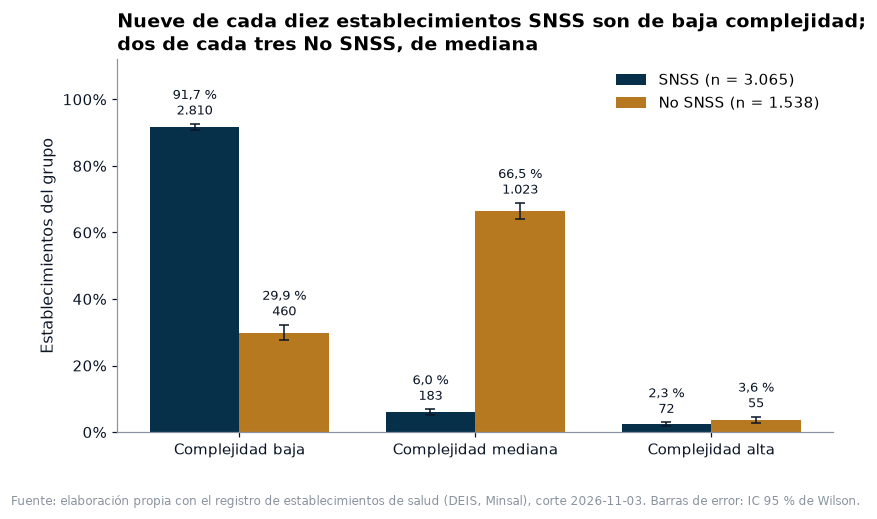

,pertenencia_snss,complejidad,n,casos,proporcion,ic_inferior,ic_superior
0,SNSS,Baja,3065,2810,0.9168,0.9065,0.9261
1,SNSS,Mediana,3065,183,0.0597,0.0519,0.0687
2,SNSS,Alta,3065,72,0.0235,0.0187,0.0295
3,No SNSS,Baja,1538,460,0.2991,0.2767,0.3225
4,No SNSS,Mediana,1538,1023,0.6651,0.6412,0.6883
5,No SNSS,Alta,1538,55,0.0358,0.0276,0.0463


In [12]:
distribucion = com.distribucion_por_grupo(legible, "pertenencia_snss", "complejidad")
proporcion = distribucion.set_index(["pertenencia_snss", "complejidad"])["proporcion"]
assert 0.90 <= proporcion[("SNSS", "Baja")] < 0.95 and 0.65 <= proporcion[("No SNSS", "Mediana")] < 0.70
assert np.allclose(distribucion.pivot(index="pertenencia_snss", columns="complejidad", values="proporcion")
                   .loc[ORDEN_GRUPOS, ORDEN_COMPLEJIDAD] * 100, porcentajes), "No coincide con los porcentajes de F3"

fig, ax = plt.subplots(figsize=(8.4, 4.4))
ancho = 0.38
for desplazamiento, grupo in [(-ancho / 2, "SNSS"), (ancho / 2, "No SNSS")]:
    datos = distribucion[distribucion["pertenencia_snss"] == grupo].set_index("complejidad").loc[ORDEN_COMPLEJIDAD]
    x = np.arange(len(ORDEN_COMPLEJIDAD)) + desplazamiento
    ax.bar(x, datos["proporcion"], width=ancho, color=COLOR_GRUPO[grupo],
           label=f"{grupo} (n = {miles(datos['n'].iloc[0])})",
           yerr=[datos["proporcion"] - datos["ic_inferior"], datos["ic_superior"] - datos["proporcion"]],
           error_kw={"ecolor": TINTA, "capsize": 3, "lw": 1})
    for xi, (_, fila) in zip(x, datos.iterrows()):
        ax.text(xi, fila["ic_superior"] + 0.015, f"{pct(fila['proporcion'], 1)}\n{miles(fila['casos'])}",
                ha="center", va="bottom", fontsize=8.5, color=TINTA)
ax.set_xticks(range(len(ORDEN_COMPLEJIDAD)), [f"Complejidad {c.lower()}" for c in ORDEN_COMPLEJIDAD])
eje_porcentaje(ax.yaxis)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Establecimientos del grupo")
ax.legend(loc="upper right")
ax.set_title("Nueve de cada diez establecimientos SNSS son de baja complejidad;\n"
             "dos de cada tres No SNSS, de mediana")
nota_fuente(fig, FUENTE + " Barras de error: IC 95 % de Wilson.")
figuras["fig4_complejidad_por_grupo"] = fig
plt.show()

distribucion.round(4)

**Lectura.**

- **Qué muestra.** El 91,7 % de los 3.065 establecimientos SNSS es de baja complejidad. Entre los 1.538 No SNSS
  predomina la mediana (66,5 %) y la baja reúne el 29,9 %. La alta complejidad es minoritaria en ambos: 2,3 % y 3,6 %.
- **Qué se infiere.** Las dos distribuciones son muy distintas, y la diferencia está en el reparto entre baja y mediana,
  no en la alta. Los intervalos son estrechos y no se superponen en baja ni en mediana.
- **Qué límite tiene.** Se cuentan establecimientos, no camas ni atenciones: un hospital de alta complejidad pesa lo
  mismo que una posta rural. La figura describe la composición de cada grupo, no su capacidad.
- **Cómo aporta al relato.** Es el contraste central. La sección siguiente mide su magnitud, y la sección 6 pregunta
  cuánto de ella se debe a que los grupos tienen distintos tipos de establecimiento.

---
## 5. Prueba de independencia y magnitud de la asociación

La Fase 1 comprometió para esta fase una prueba de independencia y una medida de magnitud, **previa revisión de sus
condiciones**. Se usa la prueba chi-cuadrado de Pearson sobre la tabla 2 × 3 y la **V de Cramér**, que lleva el
estadístico a una escala de 0 (independencia) a 1 (asociación perfecta) y no depende del tamaño de la tabla.

**Hipótesis.** La pregunta de la Fase 1 se traduce en dos hipótesis:

- **H₀ (independencia):** la distribución de la complejidad (baja, mediana, alta) es la misma en los establecimientos
  SNSS y No SNSS; conocer la pertenencia no dice nada sobre la complejidad.
- **H₁ (asociación):** la distribución de la complejidad difiere según la pertenencia al SNSS.

**Regla de decisión.** Se rechaza H₀ si el valor p es menor que 0,05. Como el valor p depende mucho del número de
establecimientos (con 4.603, diferencias pequeñas ya son «significativas»), la decisión se acompaña siempre de la
magnitud. Para la V de Cramér en una tabla con dos filas se usan como referencia los umbrales de Cohen (1988): 0,10
asociación pequeña, 0,30 mediana y 0,50 grande.

**Condición de aplicación.** La aproximación chi-cuadrado es confiable cuando todas las frecuencias esperadas bajo
independencia son al menos 5. Se revisa antes de leer el resultado.

**Cómo leer el valor p en este proyecto.** El registro contiene a todos los establecimientos de la población
delimitada, no una muestra. El valor p no se usa para «generalizar a la población», porque ya se tiene completa: se lee
como la compatibilidad de la tabla observada con un proceso en que pertenencia y complejidad fueran independientes. La
medida que importa para describir la asociación es la **V de Cramér**.

In [13]:
prueba = com.prueba_independencia(contingencia)

# Verificación independiente, sin SciPy: estadístico con la fórmula, y valor p exacto para 2 grados de libertad,
# donde la distribución chi-cuadrado tiene cola exp(-x/2)
observadas = contingencia.to_numpy(dtype=float)
esperadas_manual = np.outer(observadas.sum(axis=1), observadas.sum(axis=0)) / observadas.sum()
chi2_manual = ((observadas - esperadas_manual) ** 2 / esperadas_manual).sum()
assert np.isclose(prueba["chi2"], chi2_manual) and prueba["gl"] == 2
assert np.isclose(prueba["log10_p"], -chi2_manual / 2 / np.log(10)), "El valor p no coincide con el cálculo exacto"
assert prueba["celdas_esperada_menor_5"] == 0, "Hay frecuencias esperadas menores que 5"

print("Frecuencias esperadas bajo independencia:")
display(prueba["esperadas"].round(1))
print(f"Esperada mínima: {dec(prueba['esperada_minima'], 1)}  ->  condición de aplicación cumplida (todas ≥ 5)")

# La columna de complejidad alta es la más pequeña: se revisa por separado
esperadas_alta = prueba["esperadas"]["Alta"]
assert (esperadas_alta >= 5).all(), "Hay una celda de complejidad alta con esperada menor que 5"
print(f"Complejidad alta : {miles(int(contingencia['Alta'].sum()))} establecimientos; esperadas "
      f"{dec(esperadas_alta['SNSS'], 1)} (SNSS) y {dec(esperadas_alta['No SNSS'], 1)} (No SNSS), ambas ≥ 5\n")
print(f"Chi-cuadrado     : {dec(prueba['chi2'])} con {prueba['gl']} grados de libertad")
print(f"Valor p          : 10^{dec(prueba['log10_p'], 1)}  (SciPy lo redondea a {prueba['p']})")
print(f"V de Cramér      : {dec(prueba['v_cramer'], 3)}")

Frecuencias esperadas bajo independencia:


,Baja,Mediana,Alta
pertenencia_snss,,,
SNSS,2177.4,803.0,84.6
No SNSS,1092.6,403.0,42.4


Esperada mínima: 42,4  ->  condición de aplicación cumplida (todas ≥ 5)
Complejidad alta : 127 establecimientos; esperadas 84,6 (SNSS) y 42,4 (No SNSS), ambas ≥ 5

Chi-cuadrado     : 1.988,45 con 2 grados de libertad
Valor p          : 10^-431,8  (SciPy lo redondea a 0.0)
V de Cramér      : 0,657


**Resultado de la prueba.**

- **Condición:** ninguna frecuencia esperada queda bajo 5. La columna de complejidad alta, la más pequeña (127
  establecimientos), se revisó por separado: sus esperadas son 84,6 (SNSS) y 42,4 (No SNSS). Esta última es la menor de
  toda la tabla y está muy por encima de 5. La prueba es aplicable.
- **Decisión:** el estadístico chi-cuadrado es 1.988,45 con 2 grados de libertad y el valor p es del orden de
  10⁻⁴³². **Se rechaza H₀**: la distribución de la complejidad no es la misma en ambos grupos.
- **Magnitud:** la V de Cramér es 0,66, sobre el umbral de 0,50: según la referencia de Cohen, es una **asociación
  grande**. No es una diferencia mínima que se volvió significativa por el tamaño del registro.
- **Verificación:** el estadístico se recalculó con la fórmula, sin SciPy, y el valor p con su expresión exacta para 2
  grados de libertad (la cola de la distribución es e^(−x/2)); ambos coinciden. SciPy muestra el valor p como 0 porque
  es menor que el número más pequeño que puede representar.

### Figura 5 · Qué celdas explican la asociación

Un valor de V dice cuánta asociación hay, pero no dónde está. Los **residuos ajustados** (Agresti, 2018) comparan cada celda con lo que
habría si no hubiera asociación: un valor sobre 2 (o bajo −2) indica una celda con claramente más (o menos)
establecimientos de los esperados. Se usa un mapa de calor divergente centrado en cero, con la escala simétrica para no
exagerar ningún signo.

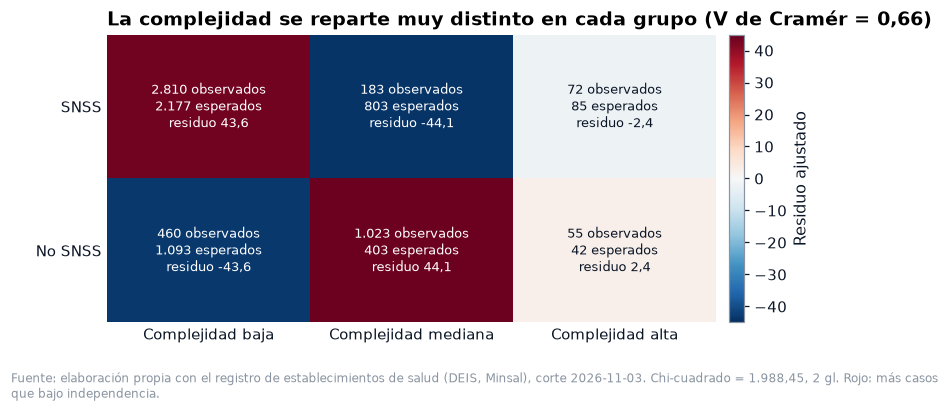

,Baja,Mediana,Alta
pertenencia_snss,,,
SNSS,43.6,-44.1,-2.4
No SNSS,-43.6,44.1,2.4


In [14]:
residuos = prueba["residuos"]
assert 0.6 <= prueba["v_cramer"] < 0.7

fig, ax = plt.subplots(figsize=(7.6, 3.4))
limite = np.ceil(np.abs(residuos.to_numpy()).max() / 5) * 5
imagen = ax.imshow(residuos.to_numpy(), cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")
for i, grupo in enumerate(residuos.index):
    for j, nivel in enumerate(residuos.columns):
        valor = residuos.iloc[i, j]
        ax.text(j, i, f"{miles(contingencia.iloc[i, j])} observados\n{dec(prueba['esperadas'].iloc[i, j], 0)} esperados\n"
                      f"residuo {dec(valor, 1)}",
                ha="center", va="center", fontsize=8.5, color="white" if abs(valor) > limite * 0.55 else TINTA)
ax.set_xticks(range(3), [f"Complejidad {c.lower()}" for c in residuos.columns])
ax.set_yticks(range(2), residuos.index)
ax.spines[["left", "bottom"]].set_visible(False)
ax.tick_params(length=0)
barra = fig.colorbar(imagen, ax=ax, fraction=0.04, pad=0.02)
barra.set_label("Residuo ajustado")
ax.set_title(f"La complejidad se reparte muy distinto en cada grupo (V de Cramér = {dec(prueba['v_cramer'], 2)})")
nota_fuente(fig, FUENTE + f" Chi-cuadrado = {dec(prueba['chi2'])}, 2 gl. Rojo: más casos que bajo independencia.")
figuras["fig5_asociacion_residuos"] = fig
plt.show()

residuos.round(1)

**Lectura.**

- **Qué muestra.** La prueba rechaza con holgura la independencia (chi-cuadrado = 1.988,45 con 2 gl) y la V de Cramér
  es 0,66. Las celdas que más se apartan son baja y mediana complejidad: hay 633 establecimientos SNSS de baja más de
  los esperados (residuo 43,6) y 620 No SNSS de mediana más de los esperados (residuo 44,1). En alta, la diferencia es
  pequeña (residuo ±2,4).
- **Qué se infiere.** Hay una asociación fuerte entre pertenencia y complejidad, y se concentra en el par
  baja-mediana.
- **Qué límite tiene.** La prueba dice que la tabla no es compatible con independencia, pero no por qué. Una tercera
  variable asociada a ambas, como el tipo de establecimiento que la Fase 1 dejó señalado como restricción, podría
  explicar parte de la asociación.
- **Cómo aporta al relato.** Responde la pregunta de investigación con una cifra, y abre la pregunta de la sección 6.

---
## 6. La asociación según el tipo de establecimiento

### 6.1 La variable de confusión que la Fase 1 dejó señalada

Una diferencia entre grupos puede deberse a una **tercera variable** relacionada con ambos. Aquí la candidata es
evidente: el tipo de establecimiento. Una posta rural es de baja complejidad por definición, y si casi todas las postas
son SNSS, la asociación entre SNSS y baja complejidad podría reflejar **qué tipos de establecimiento tiene cada grupo**
más que su pertenencia.

El registro distingue 28 tipos (`TipoEstablecimientoGlosa`). Para **describir la composición** de cada grupo
(Figura 6), el equipo los reunió en cuatro, según su función asistencial; la agrupación está declarada en
`src/configuracion.py` (`AGRUPACION_TIPOS`) y se guarda en `docs/f4/agrupacion_tipos_f4.csv`. Un tipo que no figure en
ella detiene la ejecución. Para **controlar** el tipo (sección 6.2) se usan, en cambio, los tipos originales.

In [15]:
legible["tipo"] = cruce["TipoEstablecimientoGlosa"].map(lambda t: " ".join(t.split()))
legible["tipo_agrupado"] = com.agrupar_tipos(legible["tipo"], AGRUPACION_TIPOS)

agrupacion = (legible.groupby(["tipo_agrupado", "tipo"], observed=True).size().rename("establecimientos")
              .reset_index().sort_values(["tipo_agrupado", "establecimientos"], ascending=[True, False]))
assert agrupacion["establecimientos"].sum() == N
print(f"{legible['tipo'].nunique()} tipos del registro en {len(AGRUPACION_TIPOS)} grupos\n")
print(agrupacion.groupby("tipo_agrupado", observed=True)["establecimientos"].agg(["count", "sum"])
      .rename(columns={"count": "tipos", "sum": "establecimientos"}))

28 tipos del registro en 4 grupos

                                        tipos  establecimientos
tipo_agrupado                                                  
Atención primaria y urgencia               11              2620
Hospitales y clínicas                       3               380
Centros ambulatorios y de especialidad     10              1366
Apoyo diagnóstico y otros                   4               237


**Cómo quedaron los grupos.** «Atención primaria y urgencia» reúne los establecimientos del primer nivel de atención y
de urgencia ambulatoria (postas rurales, CESFAM, CECOSF, SAPU, SAR, SUR y consultorios): son la puerta de entrada a la
red y, por definición, de baja complejidad. «Hospitales y clínicas» reúne los establecimientos con hospitalización.
«Centros ambulatorios y de especialidad» agrupa la atención ambulatoria especializada (centros de salud privados,
centros de especialidades, clínicas dentales, centros de diálisis, COSAM, entre otros). «Apoyo diagnóstico y otros»
reúne vacunatorios, salas de toma de muestras, laboratorios y la categoría «Otro» del registro.

### Figura 6 · Los grupos no tienen los mismos tipos de establecimiento

Antes de comparar la complejidad dentro de cada tipo, hay que ver si ambos grupos tienen los mismos tipos de
establecimiento. Se usan barras apiladas al 100 %, porque lo que interesa es la **composición** de cada grupo y los
grupos tienen tamaños muy distintos.

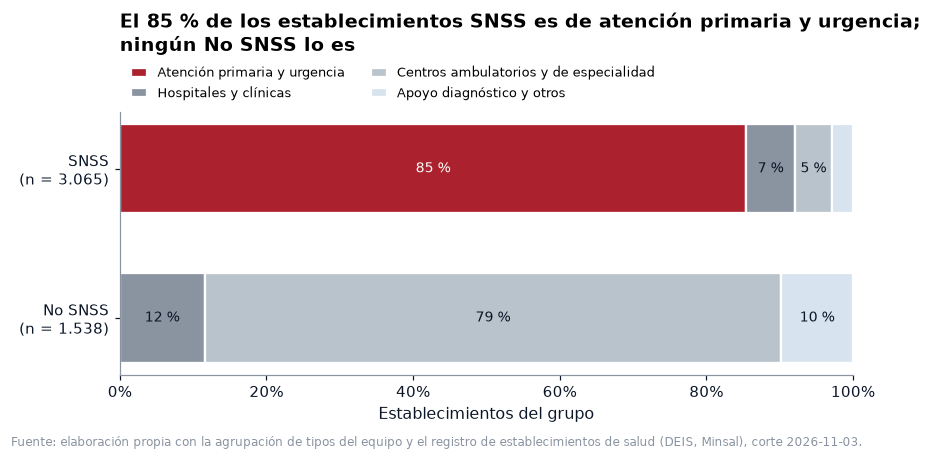

complejidad                                              Baja  Mediana  Alta
tipo_agrupado                          pertenencia_snss                     
Atención primaria y urgencia           SNSS              2616        3     1
Hospitales y clínicas                  SNSS               101       37    64
                                       No SNSS             25       98    55
Centros ambulatorios y de especialidad SNSS                 6      143     7
                                       No SNSS            291      919     0
Apoyo diagnóstico y otros              SNSS                87        0     0
                                       No SNSS            144        6     0

In [16]:
tipos_por_grupo = pd.crosstab(legible["pertenencia_snss"], legible["tipo_agrupado"]).loc[ORDEN_GRUPOS, ORDEN_TIPOS]
composicion_tipos = tipos_por_grupo.div(tipos_por_grupo.sum(axis=1), axis=0)
assert 0.85 <= composicion_tipos.loc["SNSS", "Atención primaria y urgencia"] < 0.90
assert tipos_por_grupo.loc["No SNSS", "Atención primaria y urgencia"] == 0

COLOR_TIPO = dict(zip(ORDEN_TIPOS, [GRANATE, GRIS, "#B9C3CC", HIELO]))
fig, ax = plt.subplots(figsize=(8.6, 3.1))
for fila, grupo in enumerate(reversed(ORDEN_GRUPOS)):
    izquierda = 0.0
    for tipo in ORDEN_TIPOS:
        valor = composicion_tipos.loc[grupo, tipo]
        ax.barh(fila, valor, left=izquierda, color=COLOR_TIPO[tipo], height=0.6, edgecolor="white", linewidth=1.5,
                label=tipo if fila == 0 else None)
        if valor >= 0.05:
            ax.text(izquierda + valor / 2, fila, pct(valor, 0), ha="center", va="center", fontsize=9,
                    color="white" if tipo == ORDEN_TIPOS[0] else TINTA)
        izquierda += valor
ax.set_yticks([0, 1], [f"{g}\n(n = {miles(tipos_por_grupo.loc[g].sum())})" for g in reversed(ORDEN_GRUPOS)])
eje_porcentaje(ax.xaxis)
ax.set_xlim(0, 1)
ax.set_xlabel("Establecimientos del grupo")
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8.5, handlelength=1.2)
ax.set_title("El 85 % de los establecimientos SNSS es de atención primaria y urgencia;\nningún No SNSS lo es", pad=40)
nota_fuente(fig, FUENTE.replace("elaboración propia con", "elaboración propia con la agrupación de tipos del equipo y"), altura=-0.07)
figuras["fig6_tipos_por_grupo"] = fig
plt.show()

pd.crosstab([legible["tipo_agrupado"], legible["pertenencia_snss"]], legible["complejidad"])

**Lectura.**

- **Qué muestra.** 2.620 de los 3.065 establecimientos SNSS (85,5 %) son de atención primaria y urgencia, y de ellos el
  99,8 % es de baja complejidad. El grupo No SNSS no tiene ningún establecimiento de ese tipo: se reparte entre centros
  ambulatorios y de especialidad (79 %), hospitales y clínicas (12 %) y apoyo diagnóstico (10 %).
- **Qué se infiere.** Buena parte del contraste de la Figura 4 es de **composición**: los SNSS son mayoritariamente de
  baja complejidad porque son mayoritariamente de atención primaria, un tipo que el grupo No SNSS no tiene.
- **Qué límite tiene.** En atención primaria no hay con qué comparar: sin establecimientos No SNSS de ese tipo, la
  diferencia no se puede separar del tipo con estos datos. La agrupación es una decisión del equipo; otra agrupación
  movería las cifras, aunque no la ausencia de No SNSS en atención primaria, que se ve en los 28 tipos originales.
- **Cómo aporta al relato.** Explica por qué la asociación de la sección 5 debe revisarse dentro de cada tipo.

### 6.2 La asociación dentro de los tipos presentes en ambos grupos

La Figura 6 muestra que los grupos no tienen los mismos tipos. Para controlar el tipo de establecimiento, la
comparación se repite **dentro de cada tipo del registro que tiene establecimientos SNSS y No SNSS a la vez**. Se usan
los 28 tipos originales y no la agrupación de la Figura 6, porque dentro de un grupo de tipos podrían seguir mezclándose
establecimientos distintos (por ejemplo, hospitales y clínicas). Un tipo con un solo grupo de pertenencia no permite
comparar nada, así que queda fuera.

Para cada tipo se calcula la distribución de la complejidad dentro de cada grupo (porcentaje por fila), la V de Cramér
y la frecuencia esperada mínima. La lectura compara la V del tipo con la del total (0,66), con los umbrales de Cohen:
**se mantiene** si sigue siendo grande (0,50 o más), **se reduce** si es menor y **desaparece** si ambos grupos tienen
la misma complejidad. Como varios tipos son pequeños, algunas frecuencias esperadas quedan bajo 5: en esos casos la
prueba chi-cuadrado no es confiable y la V se usa solo como **medida descriptiva** de la magnitud, sin decidir con el
valor p. Las funciones `estratos_compartidos` y `resumir_estrato` están en `src/comunicacion.py`.

In [17]:
TIPOS_COMPARTIDOS = com.estratos_compartidos(legible, "tipo", "pertenencia_snss")
compartidos = legible[legible["tipo"].isin(TIPOS_COMPARTIDOS)]
print(f"Tipos del registro: {legible['tipo'].nunique()}; con establecimientos de ambos grupos: {len(TIPOS_COMPARTIDOS)}")
print(f"Establecimientos en esos tipos: {miles(len(compartidos))} ({pct(len(compartidos) / N, 1)} de la población)\n")
assert len(TIPOS_COMPARTIDOS) == 5 and len(compartidos) == 562


def resumen(sub, nombre):
    return com.resumir_estrato(sub, nombre, "pertenencia_snss", "complejidad", ORDEN_GRUPOS, ORDEN_COMPLEJIDAD)


def cambio_respecto_del_total(v):
    # Umbrales de Cohen (1988): 0,50 o más es una asociación grande, como la del total
    if v == 0:
        return "desaparece"
    return "se mantiene" if v >= 0.5 else "se reduce"


estratos = pd.DataFrame([resumen(compartidos[compartidos["tipo"] == t], t) for t in TIPOS_COMPARTIDOS]
                        + [resumen(compartidos, "Los cinco tipos juntos"), resumen(legible, "Total de la población")])
estratos["frente_al_total"] = [cambio_respecto_del_total(v) for v in estratos["v_cramer"].iloc[:-2]] + ["", ""]
for nivel in ORDEN_COMPLEJIDAD:
    # Diferencia en puntos porcentuales: positiva cuando el nivel es más frecuente entre los SNSS
    estratos[f"dif_{nivel}_pp"] = (estratos[f"{nivel}_SNSS"] - estratos[f"{nivel}_No SNSS"]) * 100

vista = estratos.set_index("estrato")
pd.DataFrame({
    "n (SNSS / No SNSS)": [f"{miles(f['n'])} ({f['n_SNSS']} / {f['n_No SNSS']})" for _, f in vista.iterrows()],
    "Baja SNSS · No SNSS": [f"{pct(f['Baja_SNSS'], 1)} · {pct(f['Baja_No SNSS'], 1)}" for _, f in vista.iterrows()],
    "Mediana SNSS · No SNSS": [f"{pct(f['Mediana_SNSS'], 1)} · {pct(f['Mediana_No SNSS'], 1)}" for _, f in vista.iterrows()],
    "Alta SNSS · No SNSS": [f"{pct(f['Alta_SNSS'], 1)} · {pct(f['Alta_No SNSS'], 1)}" for _, f in vista.iterrows()],
    "V de Cramér": [dec(v, 2) for v in vista["v_cramer"]],
    "Esperada mínima": ["—" if pd.isna(e) else dec(e, 1) for e in vista["esperada_minima"]],
    "Frente al total": vista["frente_al_total"],
    "Lectura": vista["lectura"],
}, index=vista.index)

Tipos del registro: 28; con establecimientos de ambos grupos: 5
Establecimientos en esos tipos: 562 (12,2 % de la población)



,n (SNSS / No SNSS),Baja SNSS · No SNSS,Mediana SNSS · No SNSS,Alta SNSS · No SNSS,V de Cramér,Esperada mínima,Frente al total,Lectura
estrato,,,,,,,,
Hospital,222 (196 / 26),"51,0 % · 26,9 %","16,3 % · 11,5 %","32,7 % · 61,5 %","0,19","4,1",se reduce,esperadas < 5: leer con cautela
Clínica Dental,116 (6 / 110),"16,7 % · 3,6 %","83,3 % · 96,4 %","0,0 % · 0,0 %","0,14","0,3",se reduce,esperadas < 5: leer con cautela
Centro de Especialidades,110 (21 / 89),"4,8 % · 2,2 %","61,9 % · 97,8 %","33,3 % · 0,0 %","0,54","0,6",se mantiene,esperadas < 5: leer con cautela
Otro,103 (87 / 16),"100,0 % · 100,0 %","0,0 % · 0,0 %","0,0 % · 0,0 %","0,00",—,desaparece,sin diferencia: un solo nivel
Centro de Rehabilitación,11 (7 / 4),"28,6 % · 0,0 %","71,4 % · 100,0 %","0,0 % · 0,0 %","0,36","0,7",se reduce,esperadas < 5: leer con cautela
Los cinco tipos juntos,562 (317 / 245),"60,3 % · 11,8 %","17,4 % · 81,6 %","22,4 % · 6,5 %","0,64","37,9",,comparable
Total de la población,4.603 (3065 / 1538),"91,7 % · 29,9 %","6,0 % · 66,5 %","2,3 % · 3,6 %","0,66","42,4",,comparable


**Cómo leer la tabla.** Cada fila compara SNSS y No SNSS dentro del mismo tipo de establecimiento; los porcentajes
suman 100 % dentro de cada grupo.

- **Hospitales (222).** La V baja de 0,66 a 0,19: la asociación **se reduce** a una pequeña. Los hospitales SNSS siguen
  teniendo más baja complejidad (51,0 % frente a 26,9 %), y en alta complejidad la diferencia va en la misma dirección
  que en el total pero es mucho mayor: el 61,5 % de los hospitales No SNSS es de alta complejidad, frente al 32,7 % de
  los SNSS. Una sola celda tiene esperada bajo 5 (4,1, mediana No SNSS), por los pocos hospitales No SNSS (26).
- **Clínicas dentales (116).** La V es 0,14: casi todas son de mediana complejidad en ambos grupos. Hay solo 6 SNSS y
  las esperadas de baja complejidad quedan bajo 5, así que se lee con cautela.
- **Centros de especialidades (110).** Es el único tipo en que la asociación **se mantiene** grande (V = 0,54), pero con
  otro patrón: los No SNSS son casi todos de mediana complejidad (97,8 %) y un tercio de los SNSS es de alta (33,3 %).
  Con solo 21 SNSS, las esperadas de baja y alta complejidad quedan bajo 5.
- **«Otro» (103).** Todos son de baja complejidad en ambos grupos: la diferencia **desaparece**.
- **Centros de rehabilitación (11).** Son muy pocos (7 SNSS y 4 No SNSS) para sacar una conclusión.

**Los cinco tipos juntos dan V = 0,64**, casi lo mismo que el total, aunque dentro de cada tipo la asociación es menor.
Al juntarlos se vuelve a mezclar la composición: entre los SNSS de estos tipos predominan los hospitales y «Otro», y
entre los No SNSS, las clínicas dentales y los centros de especialidades. Por eso la comparación que controla el tipo
es la de cada fila, no la del conjunto.

In [18]:
# Revisión explícita de la complejidad alta: es la categoría con menos casos y la que cambia de dirección
legible["es_alta"] = (legible["complejidad"] == "Alta").astype(int)
TIPOS_CON_ALTA = [t for t in TIPOS_COMPARTIDOS if legible.loc[legible["tipo"] == t, "es_alta"].sum() > 0]
alta_total = com.tasa_por_grupo(legible, "pertenencia_snss", "es_alta").set_index("pertenencia_snss")
alta_por_tipo = {t: com.tasa_por_grupo(legible[legible["tipo"] == t], "pertenencia_snss", "es_alta")
                 .set_index("pertenencia_snss") for t in TIPOS_CON_ALTA}
print("Tipos compartidos con algún establecimiento de alta complejidad:", TIPOS_CON_ALTA, "\n")
pd.concat({"Total de la población": alta_total, **alta_por_tipo})[["n", "casos", "tasa", "ic_inferior", "ic_superior"]].round(3)

Tipos compartidos con algún establecimiento de alta complejidad: ['Hospital', 'Centro de Especialidades'] 



n  casos   tasa  ic_inferior  \
                         pertenencia_snss                                    
Total de la población    SNSS              3065     72  0.023        0.019   
                         No SNSS           1538     55  0.036        0.028   
Hospital                 SNSS               196     64  0.327        0.265   
                         No SNSS             26     16  0.615        0.425   
Centro de Especialidades SNSS                21      7  0.333        0.172   
                         No SNSS             89      0  0.000        0.000   

                                           ic_superior  
                         pertenencia_snss               
Total de la población    SNSS                    0.029  
                         No SNSS                 0.046  
Hospital                 SNSS                    0.395  
                         No SNSS                 0.776  
Centro de Especialidades SNSS                    0.546  
                         No SNSS                 0.041

### Figura 7 · Dentro del mismo tipo, la asociación se debilita y la alta complejidad cambia de dirección

La figura reúne las dos respuestas del control por tipo. A la izquierda, la V de Cramér dentro de cada tipo, frente a
la del total: muestra si la asociación se mantiene, se reduce o desaparece. A la derecha, la proporción de alta
complejidad en los dos tipos compartidos que la tienen, frente al total: muestra que la dirección de la diferencia
depende del tipo. Las barras parten en cero y llevan el intervalo de Wilson al 95 %.

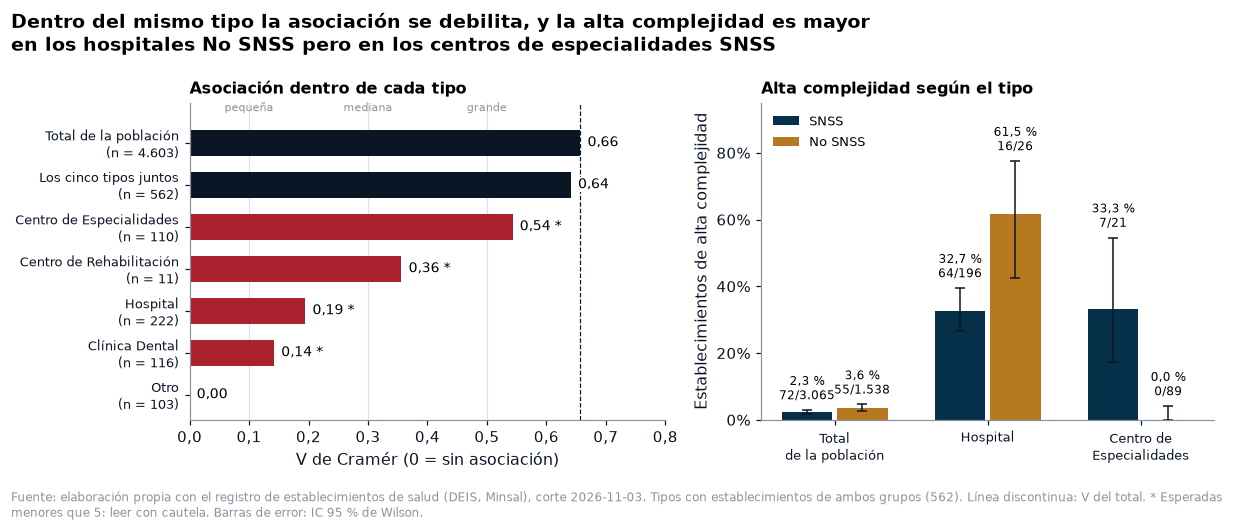

In [19]:
etiquetas_v = {"Total de la población": "Total de la población", "Los cinco tipos juntos": "Los cinco tipos juntos"}
orden_v = ["Total de la población", "Los cinco tipos juntos"] + list(
    estratos.iloc[:-2].sort_values("v_cramer", ascending=False)["estrato"])
v = estratos.set_index("estrato").loc[orden_v]

# Lo que afirma el título y la lectura, comprobado con los datos
assert v.loc["Hospital", "v_cramer"] < 0.3 and v.loc["Clínica Dental", "v_cramer"] < 0.3
assert v.loc["Centro de Especialidades", "v_cramer"] >= 0.5 and v.loc["Otro", "v_cramer"] == 0
assert alta_total.loc["No SNSS", "tasa"] > alta_total.loc["SNSS", "tasa"]
assert alta_por_tipo["Hospital"].loc["No SNSS", "tasa"] > alta_por_tipo["Hospital"].loc["SNSS", "tasa"]
assert alta_por_tipo["Centro de Especialidades"].loc["SNSS", "tasa"] > alta_por_tipo["Centro de Especialidades"].loc["No SNSS", "tasa"]

fig, (izq, der) = plt.subplots(1, 2, figsize=(11.2, 4.4), gridspec_kw={"width_ratios": [1.05, 1]})

# Panel izquierdo: V de Cramér por estrato
posiciones = np.arange(len(orden_v))[::-1]
colores = [TINTA if e in etiquetas_v else GRANATE for e in orden_v]
izq.barh(posiciones, v["v_cramer"].fillna(0), color=colores, height=0.62)
for y, e in zip(posiciones, orden_v):
    fila = v.loc[e]
    marca = " *" if fila["lectura"].startswith("esperadas") else ""
    izq.text(fila["v_cramer"] + 0.012, y, f"{dec(fila['v_cramer'], 2)}{marca}", va="center", fontsize=9,
             bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.6})
izq.set_yticks(posiciones, [f"{e}\n(n = {miles(v.loc[e, 'n'])})" for e in orden_v], fontsize=8.8)
izq.axvline(prueba["v_cramer"], color=TINTA, lw=0.8, ls="--")
for umbral, nombre in [(0.1, "pequeña"), (0.3, "mediana"), (0.5, "grande")]:
    izq.axvline(umbral, color=HIELO, lw=0.8, zorder=0)
    izq.text(umbral, len(orden_v) - 0.25, nombre, fontsize=7.5, color=GRIS, ha="center")
izq.set_xlim(0, 0.8)
izq.set_ylim(-0.6, len(orden_v) - 0.05)
izq.xaxis.set_major_formatter(lambda x, _: dec(x, 1))
izq.set_xlabel("V de Cramér (0 = sin asociación)")
izq.set_title("Asociación dentro de cada tipo", fontsize=10.5, loc="left")

# Panel derecho: alta complejidad por grupo, total y tipos con alta
paneles = [("Total de la población", alta_total)] + [(t, alta_por_tipo[t]) for t in TIPOS_CON_ALTA]
ancho = 0.36
for i, (nombre, tabla) in enumerate(paneles):
    for j, grupo in enumerate(ORDEN_GRUPOS):
        fila = tabla.loc[grupo]
        x = i + (j - 0.5) * ancho
        der.bar(x, fila["tasa"], width=ancho * 0.92, color=COLOR_GRUPO[grupo],
                yerr=[[fila["tasa"] - fila["ic_inferior"]], [fila["ic_superior"] - fila["tasa"]]],
                error_kw={"ecolor": TINTA, "capsize": 3, "lw": 1}, label=grupo if i == 0 else None)
        der.text(x, fila["ic_superior"] + 0.02, f"{pct(fila['tasa'], 1)}\n{miles(fila['casos'])}/{miles(fila['n'])}",
                 ha="center", va="bottom", fontsize=7.8)
der.set_xticks(range(len(paneles)), [n.replace(" de la población", "\nde la población").replace("Centro de ", "Centro de\n")
                                      for n, _ in paneles], fontsize=8.8)
eje_porcentaje(der.yaxis)
der.set_ylim(0, 0.95)
der.set_ylabel("Establecimientos de alta complejidad")
der.set_title("Alta complejidad según el tipo", fontsize=10.5, loc="left")
der.legend(loc="upper left", fontsize=8.5, frameon=False)

fig.suptitle("Dentro del mismo tipo la asociación se debilita, y la alta complejidad es mayor\n"
             "en los hospitales No SNSS pero en los centros de especialidades SNSS", x=0.01, ha="left",
             fontweight="bold", fontsize=12.5)
plt.tight_layout()
nota_fuente(fig, FUENTE + " Tipos con establecimientos de ambos grupos (562). Línea discontinua: V del total. "
            "* Esperadas menores que 5: leer con cautela. Barras de error: IC 95 % de Wilson.", altura=-0.01)
figuras["fig7_alta_por_tipo"] = fig
plt.show()

**Lectura.**

- **Qué muestra.** Dentro de un mismo tipo, la V de Cramér baja de 0,66 a 0,19 en hospitales y a 0,14 en clínicas
  dentales, y es 0 en «Otro»; solo en los centros de especialidades sigue siendo grande (0,54). En alta complejidad,
  el total muestra más No SNSS que SNSS (3,6 % frente a 2,3 %); en hospitales esa diferencia crece (61,5 % frente a
  32,7 %), y en centros de especialidades se invierte: 7 de 21 SNSS son de alta complejidad y ninguno de los 89 No SNSS.
- **Qué se infiere.** La asociación del total **se reduce al controlar el tipo**: buena parte de su magnitud viene de que
  cada grupo tiene tipos de establecimiento distintos. Y la diferencia en alta complejidad **no tiene una dirección
  única**: depende del tipo que se compare, así que el 3,6 % frente al 2,3 % del total no describe a ningún tipo en
  particular. Es la situación que describe la paradoja de Simpson: un dato agregado que cambia de dirección dentro de
  los subgrupos (aquí, en los centros de especialidades).
- **Qué límite tiene.** Los cinco tipos compartidos reúnen 562 establecimientos (12,2 % de la población); el resto
  pertenece a tipos que existen en un solo grupo, donde la diferencia no se puede separar del tipo. Algunos tipos son
  pequeños (21 centros de especialidades SNSS, 11 centros de rehabilitación) y tienen esperadas bajo 5. Puede haber otras
  variables de confusión: la región se revisa en la sección 6.3; otras, como la dependencia administrativa, no se miden
  aquí. Ninguna figura demuestra un efecto de la pertenencia.
- **Cómo aporta al relato.** Es el hallazgo central del control: la pertenencia **se asocia** con la complejidad, pero
  esa asociación se explica en buena parte por el tipo de establecimiento, y comparar totales lleva a una conclusión
  equivocada sobre la alta complejidad.

### 6.3 ¿La explica la región?

Las limitaciones de la sección anterior señalan otra posible variable de confusión: la región. Los grupos no se
reparten igual en el territorio (la Región Metropolitana reúne 428 de los 1.538 establecimientos No SNSS), y si las
regiones difirieran en su complejidad típica, la asociación global podría reflejar esa composición. Para descartarlo
se repite la comparación **dentro de cada una de las 16 regiones**.

La región se usa aquí **solo como estrato de control**, no para describir diferencias territoriales, que quedaron fuera
del alcance en la Fase 1. La unidad de cada punto es una región, y la medida es la proporción de establecimientos de
baja complejidad en cada grupo, el par de celdas donde se concentra la asociación (Figura 5).

In [20]:
legible["region"] = cruce["RegionGlosa"].str.strip()
por_region = (legible.assign(es_baja=(legible["complejidad"] == "Baja").astype(int))
              .groupby(["region", "pertenencia_snss"], observed=True)["es_baja"].agg(["size", "mean"])
              .unstack("pertenencia_snss"))
regiones = pd.DataFrame({
    "n_SNSS": por_region[("size", "SNSS")], "n_No_SNSS": por_region[("size", "No SNSS")],
    "baja_SNSS": por_region[("mean", "SNSS")], "baja_No_SNSS": por_region[("mean", "No SNSS")],
})
regiones["diferencia"] = regiones["baja_SNSS"] - regiones["baja_No_SNSS"]
v_region = {}
for region, sub in legible.groupby("region"):
    tabla = pd.crosstab(sub["pertenencia_snss"], sub["complejidad"])
    v_region[region] = com.prueba_independencia(tabla.loc[:, tabla.sum() > 0])["v_cramer"]
regiones["v_cramer"] = pd.Series(v_region)
regiones = regiones.sort_values("diferencia")

assert len(regiones) == 16 and regiones[["n_SNSS", "n_No_SNSS"]].min().min() > 0, "Hay regiones sin ambos grupos"
assert int(regiones[["n_SNSS", "n_No_SNSS"]].to_numpy().sum()) == N
assert (regiones["diferencia"] > 0.40).all(), "En alguna región la diferencia no se repite"
print(f"Diferencia en baja complejidad (SNSS − No SNSS): de {pct(regiones['diferencia'].min(), 1)} "
      f"a {pct(regiones['diferencia'].max(), 1)} entre regiones")
print(f"V de Cramér por región: de {dec(regiones['v_cramer'].min(), 2)} a {dec(regiones['v_cramer'].max(), 2)} "
      f"(total: {dec(prueba['v_cramer'], 2)})")
regiones.round(3)

Diferencia en baja complejidad (SNSS − No SNSS): de 42,2 % a 76,5 % entre regiones
V de Cramér por región: de 0,47 a 0,79 (total: 0,66)


,n_SNSS,n_No_SNSS,baja_SNSS,baja_No_SNSS,diferencia,v_cramer
region,,,,,,
Magallanes y de la Antártica Chilena,30,23,0.900,0.478,0.422,0.469
Antofagasta,62,69,0.887,0.464,0.423,0.484
Biobío,328,79,0.930,0.506,0.424,0.473
Aysén del General Carlos Ibañez del Campo,48,13,0.917,0.462,0.455,0.528
Tarapacá,58,31,0.879,0.419,0.460,0.514
Valparaíso,282,92,0.908,0.446,0.462,0.507
Los Lagos,333,78,0.940,0.410,0.530,0.567
Los Ríos,137,47,0.956,0.426,0.531,0.608
Atacama,58,73,0.948,0.397,0.551,0.581


### Figura 8 · Cuánto varía la baja complejidad entre regiones

Para comparar cómo se reparte una proporción entre 16 regiones se usa un **gráfico de caja con los puntos
superpuestos**: la caja resume la mediana y los cuartiles, y los puntos muestran cada región, para que se vea cuántas
observaciones hay detrás de cada caja. Con 16 valores por grupo no corresponde un gráfico de violín, que inventaría una
forma suave que los datos no tienen.

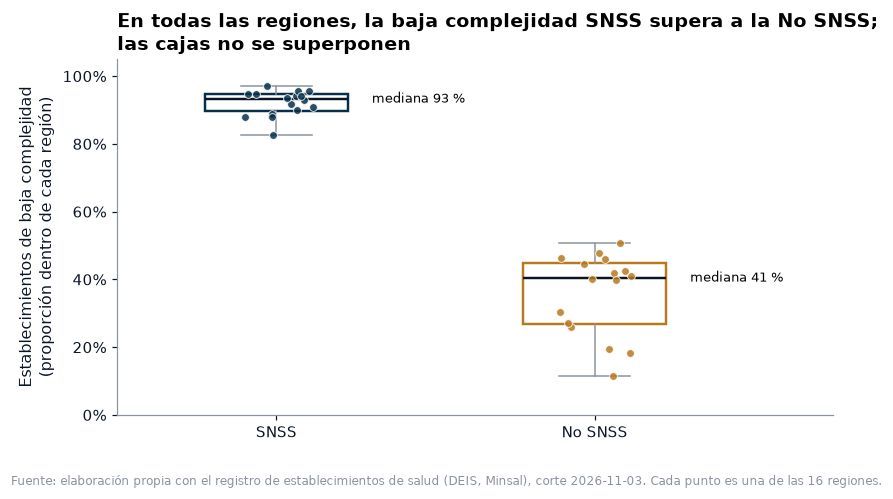

,baja_SNSS,baja_No_SNSS
count,16.000,16.000
mean,0.920,0.358
std,0.038,0.120
min,0.826,0.114
25%,0.897,0.268
50%,0.933,0.405
75%,0.947,0.450
max,0.970,0.506


In [21]:
rng = np.random.default_rng(SEMILLA)
fig, ax = plt.subplots(figsize=(8.4, 4.2))
columnas_baja = {"SNSS": "baja_SNSS", "No SNSS": "baja_No_SNSS"}
cajas = ax.boxplot([regiones[columnas_baja[g]] for g in ORDEN_GRUPOS], positions=[0, 1], widths=0.45,
                   tick_labels=ORDEN_GRUPOS, showfliers=False, patch_artist=True,
                   medianprops={"color": TINTA, "lw": 1.6}, whiskerprops={"color": GRIS}, capprops={"color": GRIS})
for caja, grupo in zip(cajas["boxes"], ORDEN_GRUPOS):
    caja.set(facecolor="white", edgecolor=COLOR_GRUPO[grupo], linewidth=1.6)
for posicion, grupo in enumerate(ORDEN_GRUPOS):
    valores = regiones[columnas_baja[grupo]]
    ax.scatter(posicion + rng.uniform(-0.12, 0.12, len(valores)), valores, s=26, color=COLOR_GRUPO[grupo],
               alpha=0.85, edgecolors="white", linewidths=0.6, zorder=3)
    ax.text(posicion + 0.3, valores.median(), f"mediana {pct(valores.median(), 0)}", va="center", fontsize=8.5)
eje_porcentaje(ax.yaxis)
ax.set_ylim(0, 1.05)
ax.set_xlim(-0.5, 1.75)
ax.set_ylabel("Establecimientos de baja complejidad\n(proporción dentro de cada región)")
ax.set_title("En todas las regiones, la baja complejidad SNSS supera a la No SNSS;\nlas cajas no se superponen")
nota_fuente(fig, FUENTE + " Cada punto es una de las 16 regiones.")
figuras["fig8_region_cajas"] = fig
plt.show()

regiones[["baja_SNSS", "baja_No_SNSS"]].describe().round(3)

**Lectura.**

- **Qué muestra.** En las 16 regiones, entre el 83 % y el 97 % de los establecimientos SNSS son de baja complejidad;
  entre los No SNSS, entre el 11 % y el 51 %. La región con menos baja complejidad SNSS (Metropolitana, 83 %) queda
  muy por encima de la región con más baja complejidad No SNSS (Biobío, 51 %).
- **Qué se infiere.** La diferencia entre grupos es mucho mayor que la variación entre regiones: la región no
  produce la asociación.
- **Qué límite tiene.** Cada punto pesa igual aunque las regiones tengan tamaños muy distintos (Aysén tiene 13
  establecimientos No SNSS y la Metropolitana, 428); la Figura 9 incorpora ese tamaño. La región tampoco controla el
  tipo de establecimiento, que sigue explicando parte de la diferencia (sección 6.2).
- **Cómo aporta al relato.** Descarta una segunda variable de confusión, la que la sección 6.2 dejó señalada.

### Figura 9 · La diferencia se repite región por región

La figura anterior compara dos distribuciones, pero no muestra si la diferencia ocurre **dentro de cada región**. Para
eso se usa una **dispersión**: cada punto es una región, con la proporción de baja complejidad No SNSS en el eje
horizontal y la SNSS en el vertical, ambos en la misma escala. La diagonal marca dónde ambos grupos serían iguales: un
punto sobre ella indica que en esa región los SNSS tienen más baja complejidad. El tamaño del punto es el número de
establecimientos de la región.

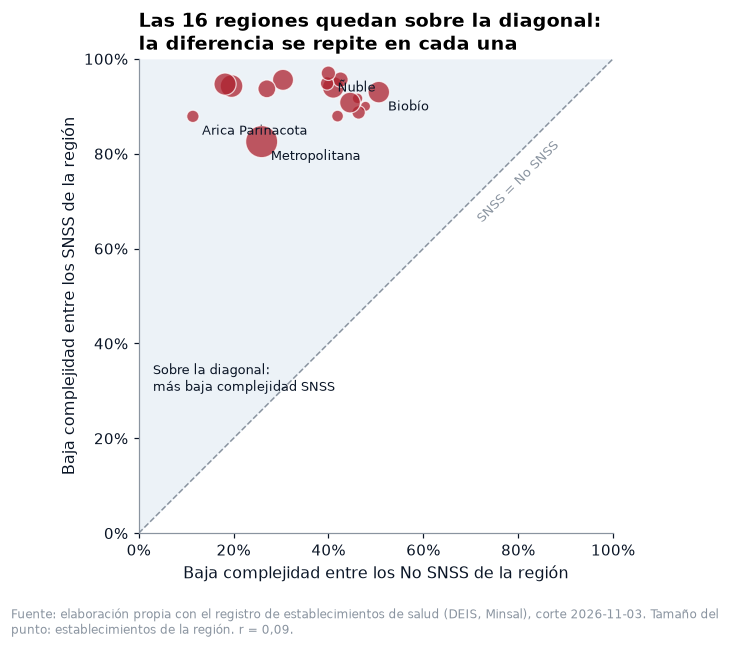

Correlación entre ambas proporciones (16 regiones): r = 0,09


In [22]:
correlacion_regiones = regiones["baja_No_SNSS"].corr(regiones["baja_SNSS"])
assert (regiones["baja_SNSS"] > regiones["baja_No_SNSS"]).all()

fig, ax = plt.subplots(figsize=(6.6, 5.6))
ax.plot([0, 1], [0, 1], color=GRIS, lw=1, ls="--")
ax.text(0.80, 0.74, "SNSS = No SNSS", color=GRIS, fontsize=8.5, rotation=45, ha="center", va="center")
ax.fill_between([0, 1], [0, 1], [1, 1], color=HIELO, alpha=0.45, lw=0)
ax.text(0.03, 0.30, "Sobre la diagonal:\nmás baja complejidad SNSS", color=TINTA, fontsize=8.5)
tamano = (regiones["n_SNSS"] + regiones["n_No_SNSS"])
ax.scatter(regiones["baja_No_SNSS"], regiones["baja_SNSS"], s=tamano / tamano.max() * 420 + 20,
           color=GRANATE, alpha=0.75, edgecolors="white", linewidths=0.8, zorder=3)
for region in ["Metropolitana de Santiago", "Arica Parinacota", "Biobío", "Ñuble"]:
    fila = regiones.loc[region]
    ax.annotate(region.replace(" de Santiago", ""), (fila["baja_No_SNSS"], fila["baja_SNSS"]),
                xytext=(6, -12), textcoords="offset points", fontsize=8.3, color=TINTA)
for eje in (ax.xaxis, ax.yaxis):
    eje_porcentaje(eje)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.set_xlabel("Baja complejidad entre los No SNSS de la región")
ax.set_ylabel("Baja complejidad entre los SNSS de la región")
ax.set_title("Las 16 regiones quedan sobre la diagonal:\nla diferencia se repite en cada una")
nota_fuente(fig, FUENTE + f" Tamaño del punto: establecimientos de la región. r = {dec(correlacion_regiones, 2)}.",
            altura=-0.01)
figuras["fig9_region_dispersion"] = fig
plt.show()

print(f"Correlación entre ambas proporciones (16 regiones): r = {dec(correlacion_regiones, 2)}")

**Lectura.**

- **Qué muestra.** Las 16 regiones quedan sobre la diagonal, todas a más de 40 puntos porcentuales de ella. Las más
  grandes (Metropolitana, Maule, Coquimbo) se comportan igual que las pequeñas. La correlación entre ambas proporciones
  es baja: que una región tenga más baja complejidad No SNSS no implica que tenga más baja complejidad SNSS.
- **Qué se infiere.** La asociación no es un efecto de agregar regiones distintas: aparece dentro de cada una. La V de
  Cramér por región va de 0,47 a 0,79, en torno al 0,66 del total (tabla de 6.3).
- **Qué límite tiene.** Es una comparación de proporciones por región, no de establecimientos individuales, y no
  controla al mismo tiempo región y tipo de establecimiento: con 16 regiones y 5 tipos compartidos, muchos estratos quedarían con
  muy pocos establecimientos.
- **Cómo aporta al relato.** Junto con la sección 6.2 delimita qué explica la asociación: el tipo de establecimiento
  explica una parte importante; la región, no.

---
## 7. Una figura que engaña, y cómo corregirla

El mismo dato puede contarse de forma honesta o engañosa. El caso más frecuente es el **eje truncado**: en una barra la
longitud codifica la magnitud, así que empezar el eje en un valor distinto de cero hace que una diferencia pequeña
parezca enorme. El **factor de mentira** de Tufte lo cuantifica: el tamaño del efecto que muestra la figura dividido
por el tamaño del efecto en los datos. Una figura honesta tiene un factor cercano a 1.

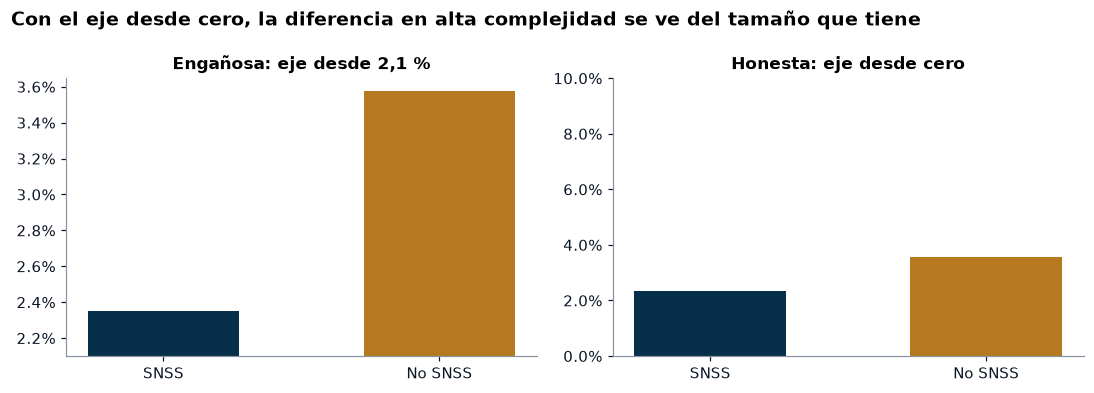

Diferencia real      : la barra mayor es 52 % más alta
Diferencia aparente  : la barra mayor parece 493 % más alta
Factor de mentira    : 9,4


In [23]:
valores = alta_total.loc[ORDEN_GRUPOS, "tasa"].to_numpy()
piso = 0.021

fig, (mal, bien) = plt.subplots(1, 2, figsize=(10, 3.6))
for eje, inicio, titulo in [(mal, piso, f"Engañosa: eje desde {pct(piso, 1)}"), (bien, 0, "Honesta: eje desde cero")]:
    eje.bar(ORDEN_GRUPOS, valores, color=[COLOR_GRUPO[g] for g in ORDEN_GRUPOS], width=0.55)
    eje.set_ylim(inicio, 0.10 if inicio == 0 else valores.max() * 1.02)
    eje.set_title(titulo, fontsize=11, loc="center")
    eje.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
fig.suptitle("Con el eje desde cero, la diferencia en alta complejidad se ve del tamaño que tiene",
             x=0.01, ha="left", fontweight="bold", fontsize=12.5)
plt.tight_layout()
plt.show()

efecto_real = valores.max() / valores.min() - 1
efecto_mostrado = (valores.max() - piso) / (valores.min() - piso) - 1
print(f"Diferencia real      : la barra mayor es {pct(efecto_real, 0)} más alta")
print(f"Diferencia aparente  : la barra mayor parece {pct(efecto_mostrado, 0)} más alta")
print(f"Factor de mentira    : {dec(efecto_mostrado / efecto_real, 1)}")

**Qué muestra el resultado.** En los datos, la proporción de alta complejidad No SNSS (3,6 %) es un 52 % mayor que la
SNSS (2,3 %). Con el eje desde 2,1 %, la barra No SNSS se ve casi seis veces más alta que la SNSS: el efecto aparente
es unas nueve veces el real (factor de mentira 9,4). Un lector que solo mirara esa figura concluiría que los No SNSS
concentran la alta complejidad, una conclusión que la Figura 7 muestra que depende del tipo: es cierta entre los
hospitales y falsa entre los centros de especialidades.

Por esta razón, todas las figuras de barras de este cuaderno parten en cero, y las que comparan grupos de distinto
tamaño muestran proporciones y no conteos. Esta figura no se lleva al informe: queda como evidencia del criterio con
que se construyeron las demás.

---
## 8. Eficiencia: reconstruir las categorías

La única operación nueva de esta fase que recorre todas las filas es la reconstrucción de las categorías a partir de la
matriz 0/1. La primera versión de `reconstruir_categorias` usaba `idxmax` de pandas, como el proyecto modelo del curso.
Antes de dejarla se compararon tres formas de hacer lo mismo, que deben dar **exactamente el mismo resultado**:

| Implementación | Cómo funciona | Complejidad temporal | Memoria adicional |
|---|---|---|---|
| Bucle de Python | Recorre cada fila y busca la columna con 1 | O(n · k), en el intérprete | O(n): una lista de n textos |
| pandas `idxmax` | Busca el máximo de cada fila y traduce el nombre de su columna | O(n · k), vectorizada | O(n): una serie de nombres y su traducción |
| NumPy `argmax` | Busca la posición del máximo; la posición ya es el código de la categoría | O(n · k), vectorizada | O(n): un arreglo de enteros |

Aquí n es el número de filas y k el de columnas indicadoras de cada variable (2 y 3). Las tres son lineales en n; lo que
cambia es dónde se ejecuta el recorrido y cuántas estructuras intermedias se crean. Se mide el tiempo con
`tiempo_minimo` (el mínimo de cinco repeticiones de `timeit`: los valores altos suelen reflejar interrupciones del
sistema y no el costo del código) sobre **tres tamaños crecientes**, replicando la población, y la memoria pico con
`tracemalloc` mediante `medir`, las mismas funciones de la Fase 3. Se mide también la función final de `src/`, que agrega
las validaciones (solo 0 y 1, una categoría activa por fila), para conocer su costo.

In [24]:
def reconstruir_con_bucle(matriz, codificaciones):
    """Versión ingenua: recorre fila por fila en Python."""
    resultado = {}
    for variable, mapa in codificaciones:
        categorias = list(mapa)
        valores = [categorias[fila.index(1)] for fila in matriz[list(mapa.values())].itertuples(index=False)]
        resultado[variable] = pd.Categorical(valores, categories=categorias)
    return pd.DataFrame(resultado, index=matriz.index)


def reconstruir_con_idxmax(matriz, codificaciones):
    """Primera versión del módulo: nombre de la columna con el máximo, traducido a su categoría."""
    resultado = {}
    for variable, mapa in codificaciones:
        categoria_por_columna = {columna: categoria for categoria, columna in mapa.items()}
        nombres = matriz[list(mapa.values())].idxmax(axis=1)
        resultado[variable] = pd.Categorical(nombres.map(categoria_por_columna), categories=list(mapa))
    return pd.DataFrame(resultado, index=matriz.index)


def reconstruir_con_argmax(matriz, codificaciones):
    """Versión NumPy: posición del 1 en cada fila, que es el código de la categoría."""
    resultado = {}
    for variable, mapa in codificaciones:
        posiciones = matriz[list(mapa.values())].to_numpy().argmax(axis=1)
        resultado[variable] = pd.Categorical.from_codes(posiciones, categories=list(mapa))
    return pd.DataFrame(resultado, index=matriz.index)


IMPLEMENTACIONES = {"Bucle de Python": reconstruir_con_bucle,
                    "pandas idxmax": reconstruir_con_idxmax,
                    "NumPy argmax": reconstruir_con_argmax,
                    "argmax + validaciones (src)": com.reconstruir_categorias}

# Primero, la equivalencia: las cuatro deben producir la misma tabla
referencia = reconstruir_con_bucle(matriz, CODIFICACIONES)
for nombre, funcion in IMPLEMENTACIONES.items():
    pd.testing.assert_frame_equal(funcion(matriz, CODIFICACIONES), referencia)
print("Las cuatro implementaciones producen el mismo resultado.\n")

filas_medicion = []
for factor in [1, 10, 50]:
    grande = pd.concat([matriz] * factor, ignore_index=True)
    for nombre, funcion in IMPLEMENTACIONES.items():
        segundos = tiempo_minimo(lambda: funcion(grande, CODIFICACIONES), repeticiones=5)
        filas_medicion.append({"filas": len(grande), "implementacion": nombre, "ms": segundos * 1000})
medicion = pd.DataFrame(filas_medicion)
tabla_tiempos = medicion.pivot(index="filas", columns="implementacion", values="ms")[list(IMPLEMENTACIONES)]
print("Tiempo mínimo en milisegundos:")
display(tabla_tiempos.round(2))

razones = pd.DataFrame({
    "bucle / argmax": tabla_tiempos["Bucle de Python"] / tabla_tiempos["NumPy argmax"],
    "idxmax / argmax": tabla_tiempos["pandas idxmax"] / tabla_tiempos["NumPy argmax"],
    "costo de las validaciones": tabla_tiempos["argmax + validaciones (src)"] / tabla_tiempos["NumPy argmax"],
})
print("Razones entre implementaciones (cuántas veces más tiempo):")
display(razones.round(1))

memoria = []
for nombre, funcion in IMPLEMENTACIONES.items():
    _, _, pico = medir(funcion, pd.concat([matriz] * 10, ignore_index=True), CODIFICACIONES)
    memoria.append({"implementacion": nombre, "memoria_pico_MB": pico})
memoria = pd.DataFrame(memoria).set_index("implementacion")
print(f"Memoria pico con {miles(10 * N)} filas:")
display(memoria.round(2))

crecimiento = tabla_tiempos.iloc[-1] / tabla_tiempos.iloc[0]
print(f"Al multiplicar las filas por {tabla_tiempos.index[-1] // tabla_tiempos.index[0]}, el tiempo se multiplica por:")
for nombre, valor in crecimiento.items():
    print(f"  {nombre:<28} {dec(valor, 1)}")

# La elección se apoya en la medición: si dejara de cumplirse, la celda se detendría
assert tabla_tiempos["NumPy argmax"].iloc[-1] < tabla_tiempos["pandas idxmax"].iloc[-1]
assert tabla_tiempos["NumPy argmax"].iloc[-1] < tabla_tiempos["Bucle de Python"].iloc[-1]
assert tabla_tiempos["argmax + validaciones (src)"].iloc[-1] < tabla_tiempos["pandas idxmax"].iloc[-1]

Las cuatro implementaciones producen el mismo resultado.



Tiempo mínimo en milisegundos:


implementacion,Bucle de Python,pandas idxmax,NumPy argmax,argmax + validaciones (src)
filas,,,,
4603,4.55,3.37,0.89,1.39
46030,32.04,15.89,2.81,3.05
230150,124.87,63.45,8.02,10.23


Razones entre implementaciones (cuántas veces más tiempo):


,bucle / argmax,idxmax / argmax,costo de las validaciones
filas,,,
4603,5.1,3.8,1.6
46030,11.4,5.6,1.1
230150,15.6,7.9,1.3


Memoria pico con 46.030 filas:


,memoria_pico_MB
implementacion,
Bucle de Python,2.99
pandas idxmax,2.91
NumPy argmax,2.86
argmax + validaciones (src),2.86


Al multiplicar las filas por 50, el tiempo se multiplica por:
  Bucle de Python              27,4
  pandas idxmax                18,9
  NumPy argmax                 9,0
  argmax + validaciones (src)  7,4


### Figura 10 · Cómo crece el costo con el volumen

Se grafican los tiempos de la tabla anterior en **escala logarítmica en ambos ejes**: así, una recta de pendiente 1
indica un crecimiento proporcional a las filas, y la distancia vertical entre dos líneas es la razón entre sus
tiempos. En un gráfico de líneas el eje puede no partir en cero, porque lo que se compara es la forma del
crecimiento y no la magnitud de una barra.

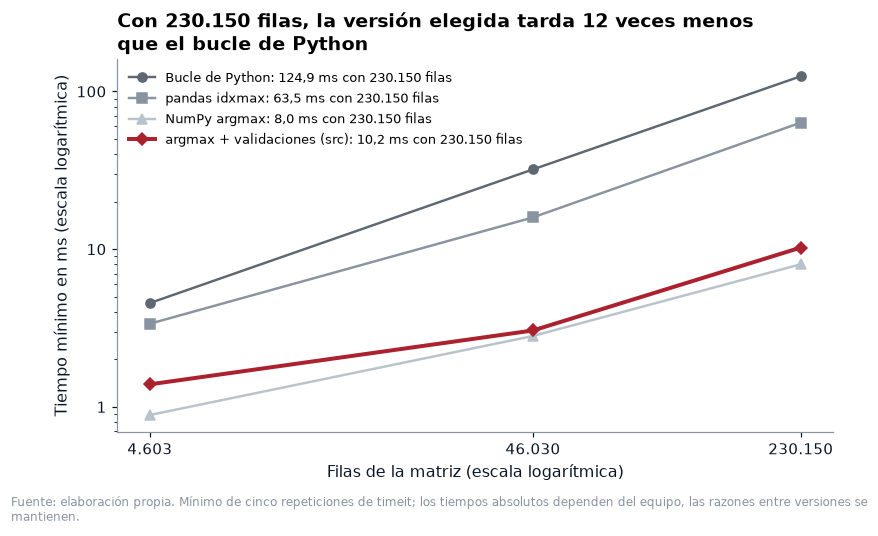

In [25]:
razon_final = tabla_tiempos["Bucle de Python"].iloc[-1] / tabla_tiempos["argmax + validaciones (src)"].iloc[-1]
assert razon_final > 5

ESTILOS = {"Bucle de Python": ("#5E6873", "o", 1.6), "pandas idxmax": (GRIS, "s", 1.6),
           "NumPy argmax": ("#B9C3CC", "^", 1.6), "argmax + validaciones (src)": (GRANATE, "D", 2.6)}
fig, ax = plt.subplots(figsize=(8.4, 4.4))
for nombre, (color, marca, grosor) in ESTILOS.items():
    serie = tabla_tiempos[nombre]
    ax.plot(serie.index, serie.to_numpy(), marker=marca, color=color, lw=grosor, ms=6,
            label=f"{nombre}: {dec(serie.iloc[-1], 1)} ms con {miles(serie.index[-1])} filas")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(tabla_tiempos.index, [miles(v) for v in tabla_tiempos.index])
ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: dec(v, 0) if v >= 1 else dec(v, 1)))
ax.set_xlabel("Filas de la matriz (escala logarítmica)")
ax.set_ylabel("Tiempo mínimo en ms (escala logarítmica)")
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title(f"Con {miles(tabla_tiempos.index[-1])} filas, la versión elegida tarda {dec(razon_final, 0)} veces "
             "menos\nque el bucle de Python")
nota_fuente(fig, "Fuente: elaboración propia. Mínimo de cinco repeticiones de timeit; los tiempos absolutos "
                 "dependen del equipo, las razones entre versiones se mantienen.")
figuras["fig10_eficiencia"] = fig
plt.show()

**Interpretación.**

- **Con el tamaño real, la diferencia no importa.** Con 4.603 filas, todas tardan unos pocos milisegundos. Si el
  proyecto solo tuviera que procesar este registro, cualquiera serviría.
- **Al crecer el volumen, el orden se ordena por dónde ocurre el recorrido.** El bucle de Python crece casi en
  proporción a las filas, porque cada fila es una iteración del intérprete. `idxmax` es vectorizada, pero crea una
  serie de nombres de columna y luego la traduce con un diccionario; `argmax` entrega directamente la posición, que ya
  es el código de la categoría, y no crea textos intermedios. Con la población replicada 50 veces, `argmax` es
  alrededor de un orden de magnitud más rápida que `idxmax` (ver la tabla de razones). A tamaños pequeños las razones
  son menores porque domina el costo fijo de preparar las estructuras.
- **En memoria no hay diferencia relevante.** Las cuatro crean una estructura proporcional a n, y sus picos son del
  mismo orden. La memoria no decide la elección.
- **Las validaciones cuestan poco y se conservan.** Comprobar que la matriz solo tiene 0 y 1 y que cada fila tiene una
  sola categoría activa agrega dos recorridos del mismo orden O(n · k): la función final tarda algo más que `argmax`
  sola (columna «costo de las validaciones») y sigue siendo varias veces más rápida que `idxmax`. A cambio, detecta
  una matriz corrupta en lugar de reconstruir categorías falsas. En una primera versión esas validaciones usaban
  `isin` de pandas y multiplicaban por cinco el tiempo de `argmax`; reescritas sobre arreglos de NumPy, el costo
  adicional quedó en torno a un tercio.

La Figura 10 resume la comparación: las cuatro líneas suben con el volumen, pero la del bucle se separa de las
vectorizadas a medida que crecen las filas, y la versión elegida (en granate) queda junto a `argmax` sola.

**Elección.** `src/comunicacion.py` quedó con **`argmax` más las validaciones**: aun validando es más rápida que
`idxmax`, no usa más memoria que las otras y produce el mismo resultado, verificado con `assert_frame_equal`. La
versión con `idxmax` se conserva en esta celda como referencia de la comparación.

---
## 9. Validación técnica

Se registran controles en tres escenarios: **casos normales** (lo que debe ocurrir con los datos reales), **casos
límite** (bordes del dominio: grupos sin casos, proporciones extremas, estratos sin comparación) y **excepciones**
(entradas que deben fallar con un mensaje claro). Cada control queda en una tabla que se guarda como evidencia.

Además, `tests/test_comunicacion.py` prueba `src/comunicacion.py` con tablas pequeñas cuyo resultado se conoce de
antemano; aquí se ejecuta y se informa su resultado, junto con las 28 pruebas del núcleo de la Fase 3.

In [26]:
controles = []


def verificar(escenario, control, condicion, detalle=""):
    controles.append({"escenario": escenario, "control": control,
                      "estado": "OK" if condicion else "FALLA", "detalle": detalle})


# Casos normales
verificar("normal", "La copia conserva las filas de la población", len(legible) == N, f"{miles(len(legible))} filas")
verificar("normal", "Cada grupo suma 100 % en la Figura 4",
          np.allclose(distribucion.groupby("pertenencia_snss", observed=True)["proporcion"].sum(), 1))
verificar("normal", "Incluidos de la Figura 2 = población", int(conteo_destino["Incluido"].sum()) == N)
verificar("normal", "Los cinco tipos compartidos suman sus 562 establecimientos",
          int(estratos["n"].iloc[:-2].sum()) == len(compartidos) == 562)
verificar("normal", "Chi-cuadrado igual a la fórmula manual", bool(np.isclose(prueba["chi2"], chi2_manual)),
          dec(prueba["chi2"]))

# Casos límite
verificar("límite", "Wilson sin casos no es negativo", com.intervalo_wilson(0, 89)[0] == 0.0,
          "alta en centros de especialidades No SNSS: 0 de 89")
verificar("límite", "Wilson con todos los casos no supera 1", com.intervalo_wilson(87, 87)[1] == 1.0)
verificar("límite", "Tipo sin No SNSS queda sin comparación",
          resumen(legible[legible["tipo"] == "Posta de Salud Rural (PSR)"], "PSR")["lectura"] == "sin comparación posible",
          "postas rurales: solo SNSS")
verificar("límite", "Categoría sin casos se conserva al reconstruir",
          list(com.reconstruir_categorias(matriz.iloc[:1], CODIFICACIONES)["complejidad"].cat.categories)
          == ORDEN_COMPLEJIDAD)

# Excepciones
for descripcion, llamada, error in [
    ("Faltan salidas de la Fase 3", lambda: com.cargar_artefactos(RAIZ / "carpeta_inexistente"), FileNotFoundError),
    ("Fila sin categoría activa", lambda: com.reconstruir_categorias(matriz.iloc[:1] * 0, CODIFICACIONES), ValueError),
    ("Tipo de establecimiento sin grupo", lambda: com.agrupar_tipos(pd.Series(["Tipo nuevo"]), AGRUPACION_TIPOS), KeyError),
    ("Tabla con una columna sin casos", lambda: com.prueba_independencia(pd.DataFrame([[3, 0], [4, 0]])), ValueError),
    ("Proporción sin observaciones", lambda: com.intervalo_wilson(0, 0), ValueError),
]:
    try:
        llamada()
        verificar("excepción", descripcion, False, "no lanzó error")
    except error as excepcion:
        verificar("excepción", descripcion, True, type(excepcion).__name__)

tabla_controles = pd.DataFrame(controles)
assert (tabla_controles["estado"] == "OK").all(), "Hay controles que fallaron"
with pd.option_context("display.max_colwidth", 60):
    display(tabla_controles)

,escenario,control,estado,detalle
0,normal,La copia conserva las filas de la población,OK,4.603 filas
1,normal,Cada grupo suma 100 % en la Figura 4,OK,
2,normal,Incluidos de la Figura 2 = población,OK,
3,normal,Los cinco tipos compartidos suman sus 562 establecimientos,OK,
4,normal,Chi-cuadrado igual a la fórmula manual,OK,"1.988,45"
5,límite,Wilson sin casos no es negativo,OK,alta en centros de especialidades No SNSS: 0 de 89
6,límite,Wilson con todos los casos no supera 1,OK,
7,límite,Tipo sin No SNSS queda sin comparación,OK,postas rurales: solo SNSS
8,límite,Categoría sin casos se conserva al reconstruir,OK,
9,excepción,Faltan salidas de la Fase 3,OK,FileNotFoundError


In [27]:
import io
import unittest

cargador = unittest.TestLoader()
suite = unittest.TestSuite([cargador.loadTestsFromName("tests.test_comunicacion"),
                            cargador.loadTestsFromName("tests.test_nucleo")])
salida = io.StringIO()
resultado_pruebas = unittest.TextTestRunner(stream=salida, verbosity=0).run(suite)
assert resultado_pruebas.wasSuccessful(), salida.getvalue()
n_comunicacion = cargador.loadTestsFromName("tests.test_comunicacion").countTestCases()
print(f"Pruebas automatizadas: {resultado_pruebas.testsRun} ejecutadas, todas correctas "
      f"({n_comunicacion} de src/comunicacion.py y {resultado_pruebas.testsRun - n_comunicacion} del núcleo de F3).")

Pruebas automatizadas: 53 ejecutadas, todas correctas (23 de src/comunicacion.py y 30 del núcleo de F3).


**Qué protege cada escenario en este proyecto.**

- **Casos normales:** que las cifras que se comunican cuadren entre sí. La población debe ser 4.603 en la copia, en la
  Figura 2 y en la suma de los tipos compartidos; cada grupo debe sumar 100 % en la Figura 4; el chi-cuadrado debe coincidir con
  la fórmula. Si alguno fallara, el informe tendría cifras que no suman.
- **Casos límite:** situaciones reales de nuestros datos en el borde de lo que calculan las funciones. Hay un estrato con
  0 establecimientos de alta complejidad (centros ambulatorios No SNSS, 0 de 1.210), uno sin establecimientos No SNSS
  (atención primaria) y categorías sin casos al reconstruir una sola fila. Las funciones deben dar resultados válidos
  (un intervalo que no sea negativo, una comparación marcada como imposible) y no un error ni un número sin sentido.
- **Excepciones:** entradas que deben detener la ejecución con un mensaje claro: que falten salidas de la Fase 3, que
  una fila de la matriz no tenga categoría, que aparezca un tipo de establecimiento nuevo en el registro, que una tabla
  tenga una columna vacía o que se pida una proporción sin observaciones. En todos los casos, detenerse es preferible a
  producir una figura incorrecta.

Los 14 controles son correctos y las 48 pruebas automatizadas también, lo que significa que el módulo de esta fase y el
núcleo de la Fase 3 se comportan como se espera en los tres escenarios.

---
## 10. Persistencia: lo que se lleva al informe y al video

Las figuras se guardan en `F4/figuras/` a 200 ppp, resolución suficiente para el informe impreso. Los hallazgos se
guardan en `docs/hallazgos_f4.csv` con la cifra exacta que los respalda: el texto del informe y el guion del video se
escriben desde esa misma fuente. Las tablas de las que salen las figuras van a `docs/f4/`.

In [28]:
rutas = {nombre: com.guardar_figura(figura, DIR_FIGURAS, nombre) for nombre, figura in figuras.items()}

hosp = alta_por_tipo["Hospital"]
especialidades = alta_por_tipo["Centro de Especialidades"]
v_tipo = estratos.set_index("estrato")["v_cramer"]
hallazgos = pd.DataFrame([
    {"figura": "fig1_alcance_poblacion", "uso": "anexo",
     "hallazgo": "F01 y F07 explican la mayor parte de las exclusiones",
     "evidencia": f"De {miles(len(original))} registros quedan {miles(N)}; F01 y F07 reúnen el "
                  f"{pct(proporcion_principales, 0)} de las {miles(filtros['excluidos'].sum())} exclusiones"},
    {"figura": "fig2_exclusiones_por_grupo", "uso": "anexo",
     "hallazgo": "La menor retención No SNSS se debe al filtro de complejidad «No Aplica»",
     "evidencia": f"F07 excluye {miles(conteo_destino.loc['No SNSS', 'F07'])} registros No SNSS "
                  f"({pct(f07_no_snss, 1)}) frente a {miles(conteo_destino.loc['SNSS', 'F07'])} SNSS"},
    {"figura": "fig3_estandarizacion", "uso": "anexo",
     "hallazgo": "Sin estandarizar la escritura de las categorías se habrían perdido establecimientos No SNSS",
     "evidencia": f"{total_afectados} establecimientos escritos con la forma minoritaria, "
                  f"{afectados.loc['No SNSS'].sum()} de ellos No SNSS"},
    {"figura": "fig4_complejidad_por_grupo", "uso": "informe",
     "hallazgo": "SNSS concentra la baja complejidad y No SNSS la mediana",
     "evidencia": f"Baja: {pct(proporcion[('SNSS', 'Baja')], 1)} en SNSS; mediana: "
                  f"{pct(proporcion[('No SNSS', 'Mediana')], 1)} en No SNSS"},
    {"figura": "fig5_asociacion_residuos", "uso": "informe",
     "hallazgo": "La asociación entre pertenencia y complejidad es fuerte",
     "evidencia": f"Chi-cuadrado = {dec(prueba['chi2'])} (2 gl), V de Cramér = {dec(prueba['v_cramer'], 3)}"},
    {"figura": "fig6_tipos_por_grupo", "uso": "anexo",
     "hallazgo": "Los grupos tienen tipos de establecimiento distintos",
     "evidencia": f"{pct(composicion_tipos.loc['SNSS', 'Atención primaria y urgencia'], 1)} de los SNSS son de "
                  "atención primaria y urgencia; ningún No SNSS"},
    {"figura": "fig7_alta_por_tipo", "uso": "informe",
     "hallazgo": "Dentro de los tipos presentes en ambos grupos la asociación se reduce, y la alta complejidad cambia de dirección según el tipo",
     "evidencia": f"V de Cramér: {dec(prueba['v_cramer'], 2)} en el total; {dec(v_tipo['Hospital'], 2)} en hospitales, "
                  f"{dec(v_tipo['Clínica Dental'], 2)} en clínicas dentales y {dec(v_tipo['Centro de Especialidades'], 2)} en "
                  f"centros de especialidades. Alta: {pct(hosp.loc['No SNSS', 'tasa'], 1)} No SNSS frente a "
                  f"{pct(hosp.loc['SNSS', 'tasa'], 1)} SNSS en hospitales; {pct(especialidades.loc['SNSS', 'tasa'], 1)} SNSS "
                  f"frente a {pct(especialidades.loc['No SNSS', 'tasa'], 1)} No SNSS en centros de especialidades"},
    {"figura": "fig8_region_cajas", "uso": "anexo",
     "hallazgo": "La diferencia en baja complejidad es mayor que la variación entre regiones",
     "evidencia": f"SNSS: {pct(regiones['baja_SNSS'].min(), 0)} a {pct(regiones['baja_SNSS'].max(), 0)}; "
                  f"No SNSS: {pct(regiones['baja_No_SNSS'].min(), 0)} a {pct(regiones['baja_No_SNSS'].max(), 0)}"},
    {"figura": "fig9_region_dispersion", "uso": "anexo",
     "hallazgo": "La asociación se repite dentro de cada región",
     "evidencia": f"16 de 16 regiones con más baja complejidad SNSS; diferencia mínima de "
                  f"{pct(regiones['diferencia'].min(), 1)}"},
    {"figura": "fig10_eficiencia", "uso": "anexo",
     "hallazgo": "La reconstrucción con argmax es la más rápida al crecer el volumen",
     "evidencia": f"Con {miles(tabla_tiempos.index[-1])} filas, {dec(razon_final, 0)} veces más rápida que el bucle de Python"},
])
hallazgos.to_csv(RAIZ / "docs/hallazgos_f4.csv", index=False, encoding="utf-8-sig")

tablas = {
    "vinculacion_f4.csv": vinculacion,
    "destino_por_grupo_f4.csv": conteo_destino.reset_index(),
    "distribucion_por_grupo_f4.csv": distribucion,
    "prueba_independencia_f4.csv": pd.DataFrame([{k: v for k, v in prueba.items()
                                                  if not isinstance(v, pd.DataFrame)}]),
    "residuos_ajustados_f4.csv": residuos.reset_index(),
    "agrupacion_tipos_f4.csv": agrupacion,
    "estratos_tipo_f4.csv": estratos,
    "eficiencia_f4.csv": medicion,
    "controles_f4.csv": tabla_controles,
}
for archivo, tabla in tablas.items():
    tabla.to_csv(DIR_DOCS_F4 / archivo, index=False, encoding="utf-8-sig")

metadatos = {
    "fase": 4,
    "fecha_ejecucion": date.today().isoformat(),
    "semilla": SEMILLA,
    "python": sys.version.split()[0],
    "dependencias": declaradas,
    "sha256_original": METADATOS_F3["sha256_original"],
    "filas_poblacion": N,
    "prueba_independencia": {"chi2": round(prueba["chi2"], 4), "gl": prueba["gl"],
                             "log10_p": round(prueba["log10_p"], 2), "v_cramer": round(prueba["v_cramer"], 4),
                             "esperada_minima": round(prueba["esperada_minima"], 2)},
    "figuras": {nombre: ruta.relative_to(RAIZ).as_posix() for nombre, ruta in rutas.items()},
    "controles": len(tabla_controles),
    "pruebas_automatizadas": resultado_pruebas.testsRun,
}
(DIR_DOCS_F4 / "metadatos_f4.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")

for nombre, ruta in rutas.items():
    assert ruta.is_file() and ruta.stat().st_size > 0
    print(f"{nombre:<28} {ruta.relative_to(RAIZ).as_posix():<44} ({ruta.stat().st_size / 1024:.0f} KB)")
print(f"\nHallazgos : docs/hallazgos_f4.csv ({len(hallazgos)} filas)")
print(f"Tablas    : {len(tablas)} archivos en docs/f4/")
print("Metadatos : docs/f4/metadatos_f4.json")
with pd.option_context("display.max_colwidth", 120):
    display(hallazgos)

fig1_alcance_poblacion       F4/figuras/fig1_alcance_poblacion.png        (155 KB)
fig2_exclusiones_por_grupo   F4/figuras/fig2_exclusiones_por_grupo.png    (103 KB)
fig3_estandarizacion         F4/figuras/fig3_estandarizacion.png          (121 KB)
fig4_complejidad_por_grupo   F4/figuras/fig4_complejidad_por_grupo.png    (119 KB)
fig5_asociacion_residuos     F4/figuras/fig5_asociacion_residuos.png      (146 KB)
fig6_tipos_por_grupo         F4/figuras/fig6_tipos_por_grupo.png          (108 KB)
fig7_alta_por_tipo           F4/figuras/fig7_alta_por_tipo.png            (219 KB)
fig8_region_cajas            F4/figuras/fig8_region_cajas.png             (109 KB)
fig9_region_dispersion       F4/figuras/fig9_region_dispersion.png        (152 KB)
fig10_eficiencia             F4/figuras/fig10_eficiencia.png              (156 KB)

Hallazgos : docs/hallazgos_f4.csv (10 filas)
Tablas    : 9 archivos en docs/f4/
Metadatos : docs/f4/metadatos_f4.json


,figura,uso,hallazgo,evidencia
0,fig1_alcance_poblacion,anexo,F01 y F07 explican la mayor parte de las exclusiones,De 5.837 registros quedan 4.603; F01 y F07 reúnen el 92 % de las 1.234 exclusiones
1,fig2_exclusiones_por_grupo,anexo,La menor retención No SNSS se debe al filtro de complejidad «No Aplica»,"F07 excluye 686 registros No SNSS (27,4 %) frente a 17 SNSS"
2,fig3_estandarizacion,anexo,Sin estandarizar la escritura de las categorías se habrían perdido establecimientos No SNSS,"92 establecimientos escritos con la forma minoritaria, 78 de ellos No SNSS"
3,fig4_complejidad_por_grupo,informe,SNSS concentra la baja complejidad y No SNSS la mediana,"Baja: 91,7 % en SNSS; mediana: 66,5 % en No SNSS"
4,fig5_asociacion_residuos,informe,La asociación entre pertenencia y complejidad es fuerte,"Chi-cuadrado = 1.988,45 (2 gl), V de Cramér = 0,657"
5,fig6_tipos_por_grupo,anexo,Los grupos tienen tipos de establecimiento distintos,"85,5 % de los SNSS son de atención primaria y urgencia; ningún No SNSS"
6,fig7_alta_por_tipo,informe,"Dentro de los tipos presentes en ambos grupos la asociación se reduce, y la alta complejidad cambia de dirección seg...","V de Cramér: 0,66 en el total; 0,19 en hospitales, 0,14 en clínicas dentales y 0,54 en centros de especialidades. Al..."
7,fig8_region_cajas,anexo,La diferencia en baja complejidad es mayor que la variación entre regiones,SNSS: 83 % a 97 %; No SNSS: 11 % a 51 %
8,fig9_region_dispersion,anexo,La asociación se repite dentro de cada región,"16 de 16 regiones con más baja complejidad SNSS; diferencia mínima de 42,2 %"
9,fig10_eficiencia,anexo,La reconstrucción con argmax es la más rápida al crecer el volumen,"Con 230.150 filas, 12 veces más rápida que el bucle de Python"


**Qué queda guardado y quién lo usa.**

| Archivo | Contenido | Quién lo usa |
|---|---|---|
| `F4/figuras/fig*.png` | Las diez figuras, a 200 ppp | El informe (Figuras 4, 5 y 7 en el cuerpo; el resto en anexos) y el video |
| `docs/hallazgos_f4.csv` | Un hallazgo por figura, con la cifra exacta y si va al informe o a los anexos | La redacción de Resultados y Discusión, y el guion del video |
| `docs/f4/vinculacion_f4.csv` | Objetivo, pregunta, figura y tipo de gráfico | La sección de metodología del informe |
| `docs/f4/prueba_independencia_f4.csv` y `residuos_ajustados_f4.csv` | Estadístico, grados de libertad, valor p, V de Cramér y residuos | Resultados |
| `docs/f4/estratos_tipo_f4.csv` y `agrupacion_tipos_f4.csv` | La comparación dentro de los 5 tipos compartidos (562) y la agrupación de la Figura 6 | Resultados, discusión y anexos |
| `docs/f4/destino_por_grupo_f4.csv` y `distribucion_por_grupo_f4.csv` | Las tablas de las Figuras 2 y 4 | Anexos |
| `docs/f4/eficiencia_f4.csv` y `controles_f4.csv` | Mediciones y controles de validación | Metodología y validación |
| `docs/f4/metadatos_f4.json` | Fecha, versiones, huella del archivo y resultados principales | Reproducibilidad |

Escribir el informe y el video desde estos archivos, y no copiando cifras a mano, evita que los tres productos digan
cosas distintas.

---
## 11. Respuesta a la pregunta, relato y cierre

### Respuesta a la pregunta de investigación

**¿Existe asociación entre la pertenencia al SNSS y el nivel de complejidad en los establecimientos vigentes, con
código único y ambas variables informadas?**

**Sí. La asociación existe y es grande, pero buena parte de su magnitud se explica por el tipo de establecimiento.**

1. **Existe.** Se rechaza la hipótesis de independencia (chi-cuadrado = 1.988,45, 2 gl, p del orden de 10⁻⁴³²), con
   todas las frecuencias esperadas sobre 42.
2. **Es grande y tiene una forma precisa.** La V de Cramér es 0,66. Nueve de cada diez establecimientos SNSS son de
   baja complejidad y dos de cada tres No SNSS son de mediana; en alta complejidad la diferencia es pequeña (2,3 % y
   3,6 %).
3. **Se explica en buena parte por el tipo de establecimiento.** El 85 % de los SNSS son de atención primaria y
   urgencia, un tipo que no existe entre los No SNSS. Dentro de los cinco tipos que tienen ambos grupos (562
   establecimientos), la asociación **se reduce** en hospitales (V = 0,19) y clínicas dentales (0,14), **desaparece** en
   «Otro» y solo **se mantiene** grande en los centros de especialidades (0,54).
4. **No la explica la región.** La diferencia en baja complejidad se repite en las 16 regiones, con V de Cramér entre
   0,47 y 0,79.
5. **En alta complejidad, la dirección depende del tipo.** En el total, los No SNSS tienen algo más de alta
   complejidad (3,6 % frente a 2,3 %). Entre los hospitales la diferencia es mucho mayor (61,5 % frente a 32,7 %), y
   en los centros de especialidades se invierte (33,3 % de los SNSS frente a ninguno de los No SNSS). El dato del total
   no describe a ningún tipo en particular.
6. **No es una relación causal.** Los datos son observacionales y de un solo corte. Lo que se afirma es que ambas
   variables están asociadas, no que pertenecer o no al SNSS determine la complejidad de un establecimiento.

### Qué significa para la red asistencial

Leída con esos límites, la evidencia describe una **división de funciones** más que dos redes paralelas: el SNSS
sostiene toda la atención primaria y de urgencia del registro (de baja complejidad, y con establecimientos en las 16 regiones),
mientras que los establecimientos No SNSS se concentran en la atención ambulatoria especializada de mediana
complejidad. En alta complejidad, los hospitales No SNSS son proporcionalmente más complejos, pero son pocos (26):
el SNSS aporta 64 de los 80 hospitales de alta complejidad de los tipos compartidos. Para la
planificación y la coordinación de derivaciones, esto sugiere que la complementariedad entre ambos sectores está
sobre todo en el nivel de mediana complejidad. Es una lectura descriptiva: medir la capacidad real exigiría datos de
camas, atenciones y población cubierta, que este registro no contiene.

### Mejoras propuestas a partir de la evidencia

1. **Analizar la sensibilidad a la exclusión de F07.** 686 establecimientos No SNSS quedaron fuera por complejidad «No
   Aplica». Un análisis que los trate como una cuarta categoría mostraría cuánto cambia la distribución No SNSS.
2. **Controlar tipo y región a la vez.** Un modelo de regresión logística multinomial permitiría estimar la asociación
   ajustando por ambas variables, lo que la estratificación simple no puede hacer sin dejar estratos casi vacíos.
3. **Ampliar la comparación por tipo**, por ejemplo por nivel de atención (`NivelAtencionEstabglosa`), para incluir
   a los establecimientos de los tipos que existen en un solo grupo y que hoy no se pueden comparar.
4. **Incorporar una medida de capacidad** (camas o atenciones) si se dispone de otra fuente, para pasar de contar
   establecimientos a describir capacidad resolutiva.

### El relato en tres actos

El informe y el video cuentan lo mismo. Las tres figuras marcadas como «informe» en
`docs/hallazgos_f4.csv` son las del cuerpo del informe; las otras siete respaldan la metodología y pueden ir a los
anexos.

**Acto 1 · El problema.** En Chile coexisten establecimientos que pertenecen al SNSS y otros que no, y la complejidad
de cada uno importa para la derivación de pacientes y la planificación de la red. En la población estudiada, 4.603
establecimientos vigentes (Figura 1), la complejidad se reparte de forma muy distinta: nueve de cada diez SNSS son de baja
complejidad y dos de cada tres No SNSS, de mediana (Figura 4).

**Acto 2 · Lo que muestran los datos.** La asociación es fuerte (V de Cramér = 0,66) y se concentra en el par
baja-mediana (Figura 5). Pero los grupos no tienen los mismos tipos de establecimiento: el 85 % de los SNSS es de
atención primaria y urgencia, y ningún No SNSS lo es (Figura 6).

**Acto 3 · Lo que significa y sus límites.** Al comparar el mismo tipo de establecimiento, la asociación se debilita
(V = 0,19 en hospitales) y la diferencia en alta complejidad cambia de dirección según el tipo (Figura 7). La
región, en cambio, no la explica: la diferencia se repite en las 16 regiones (Figuras 8 y 9). La
asociación existe, pero buena parte de su magnitud refleja la composición por tipo, y no se puede atribuir a la
pertenencia como causa. Además, 686 establecimientos No SNSS quedaron fuera por complejidad «No Aplica» (Figura 2), y las cifras dependen
de decisiones de preparación que se midieron, como la estandarización de las categorías (Figura 3).

### Limitaciones que el informe debe declarar

1. **Los datos son secundarios** y son un corte del registro: no se controló su recolección, y la fecha exacta de
   corte no está acreditada.
2. **Se cuentan establecimientos**, no camas, atenciones ni capacidad resolutiva.
3. **La población excluye 686 registros No SNSS con complejidad «No Aplica»**, cuya complejidad real se desconoce.
4. **Asociación no es causalidad.** El tipo de establecimiento explica parte de la asociación; la región no la
   explica, y puede haber otras variables de confusión no medidas (por ejemplo, la dependencia administrativa).
5. **El control por tipo cubre solo los 562 establecimientos de los cinco tipos compartidos** (12,2 % de la
   población). En los demás tipos, por ejemplo en atención primaria, no hay comparación posible porque existe un solo
   grupo; y algunos tipos compartidos son pequeños, con esperadas bajo 5.
6. **El valor p no generaliza**: el registro contiene a toda la población delimitada, y la magnitud se lee en la V de
   Cramér.

### Supuestos de la Fase 1, revisados

| Supuesto | Estado al cierre |
|---|---|
| Pertenencia y complejidad están bien registradas en la fuente | Se comprobó la consistencia interna y con el archivo original (2.4); la exactitud externa no se puede verificar |
| Cada código vigente identifica un único establecimiento | Comprobado: 4.603 códigos sin repetición |
| La vigencia se define por el estado registrado | Aplicado en F01; su peso es parecido en ambos grupos (Figura 2) |
| «No Aplica» es una categoría distinta de una celda vacía | Se trató por separado (F06 y F07); F07 concentra las exclusiones No SNSS |

### Puntos pendientes de las fases anteriores que se cierran aquí

| Punto | Qué se hizo en esta fase |
|---|---|
| Fijar la versión de SciPy al usarla | `scipy==1.18.1` en `requirements.txt`; F1 y esta fase comprueban el entorno |
| Revisar las frecuencias esperadas antes de la prueba e informar la V de Cramér | Sección 5: todas las esperadas son mayores que 42; V = 0,66 |
| Desglosar por filtro y grupo la menor retención No SNSS | Figura 2: 686 de las 731 exclusiones No SNSS por complejidad ocurren en F07 |
| Controlar el tipo de establecimiento como variable de confusión | Sección 6.2 y Figura 7: comparación dentro de los 5 tipos presentes en ambos grupos (562); además, por región (Figuras 8 y 9) |

### Guion del video

El video sigue el guion que escribió el grupo, en cuatro partes consecutivas, una por integrante. Cada uno presenta
la parte en que trabajó: Brian, el problema y la población (acto 1); Karla, la metodología; Kattia, los resultados y
las exclusiones (acto 2); Christopher, el tipo de establecimiento, la región y la respuesta (acto 3). Cada figura que
se comenta queda en pantalla y su título se lee en voz alta, porque el título es el hallazgo.

La tabla siguiente es ese guion, segmento por segmento, con lo que se dice, lo que se muestra y cuánto dura en el
video final. Los tiempos se midieron sobre el video publicado: cada segmento va desde que aparece su diapositiva hasta
que aparece la siguiente, y cada tramo, desde que el integrante aparece en cámara hasta que lo reemplaza el siguiente.
La celda informa la duración total frente al rango de 5 a 8 minutos y comprueba que hablen los cuatro integrantes,
que cada uno tenga un solo tramo continuo, que los tramos coincidan con los medidos y que las tres figuras del
informe se comenten.

<!-- CAMBIO (Fase 4, video final): antes los segundos eran una estimación del guion (7:20 en total); ahora son los
tiempos medidos en el video publicado (8:36). Ver el comentario de la celda siguiente. -->

In [29]:
# El guion del video replica el documento «Guion del video» del grupo: cuatro partes consecutivas, una por integrante.
# Cada fila es un segmento del texto hablado; «pantalla» indica la figura o diapositiva que se muestra mientras tanto.
# --- CAMBIO (Fase 4, video final) ---
# Antes: los segundos se estimaban con unas 135 palabras por minuto y sumaban 7:20.
# Problema: el video grabado no dura lo estimado, y la tabla describía un video que no es el que se entrega.
# Ahora: los segundos se midieron en el video publicado (8:36), según los cambios de diapositiva y de presentador.
#   Los dos segmentos de la Figura 5 se unieron en uno, porque la diapositiva es la misma (30 s en pantalla).
guion = pd.DataFrame([
    # Parte 1 · Brian Cerda · Apertura y problema (0:00 – 2:44)
    {"parte": "1 · Apertura y problema", "integrante": "Brian Cerda", "pantalla": "Portada",
     "contenido": "Saludo, integrantes y título del proyecto", "segundos": 24},
    {"parte": "1 · Apertura y problema", "integrante": "Brian Cerda", "pantalla": "Pregunta de investigación",
     "contenido": "Por qué importa la complejidad en la red asistencial y pregunta de investigación", "segundos": 87},
    {"parte": "1 · Apertura y problema", "integrante": "Brian Cerda", "pantalla": "Figura 1",
     "contenido": "De 5.837 registros a 4.603 establecimientos con ocho criterios; F01 y F07 explican el 92 % de las exclusiones",
     "segundos": 53},
    # Parte 2 · Karla Martínez · Metodología (2:44 – 4:39)
    {"parte": "2 · Metodología", "integrante": "Karla Martínez", "pantalla": "Cuatro fases encadenadas",
     "contenido": "Cuatro fases encadenadas, clases y pipeline, resultados idénticos entre fases", "segundos": 34},
    {"parte": "2 · Metodología", "integrante": "Karla Martínez", "pantalla": "Figura 3",
     "contenido": "Estandarización: 92 establecimientos, 78 No SNSS, habrían quedado fuera", "segundos": 41},
    {"parte": "2 · Metodología", "integrante": "Karla Martínez", "pantalla": "Figura 10",
     "contenido": "Eficiencia de la reconstrucción y reproducibilidad (versiones fijas, huella del archivo, 53 pruebas)",
     "segundos": 40},
    # Parte 3 · Kattia Espinoza · Resultados (4:39 – 6:24)
    {"parte": "3 · Resultados", "integrante": "Kattia Espinoza", "pantalla": "Figura 4",
     "contenido": "Nueve de cada diez SNSS son de baja complejidad y dos de cada tres No SNSS, de mediana", "segundos": 51},
    {"parte": "3 · Resultados", "integrante": "Kattia Espinoza", "pantalla": "Figura 5",
     "contenido": "Hipótesis nula, esperadas sobre 42, chi-cuadrado, V de Cramér 0,66 y residuos; la magnitud pesa más que el valor p",
     "segundos": 30},
    {"parte": "3 · Resultados", "integrante": "Kattia Espinoza", "pantalla": "Figura 2",
     "contenido": "Limitación: más de uno de cada cuatro No SNSS quedó fuera por complejidad «No Aplica»",
     "segundos": 24},
    # Parte 4 · Christopher Ulloa · Lo que hay detrás, conclusiones y cierre (6:24 – 8:36)
    {"parte": "4 · Lo que hay detrás y cierre", "integrante": "Christopher Ulloa", "pantalla": "Figura 6",
     "contenido": "El 85 % de los SNSS es de atención primaria y urgencia; ningún No SNSS lo es", "segundos": 29},
    {"parte": "4 · Lo que hay detrás y cierre", "integrante": "Christopher Ulloa", "pantalla": "Figura 7",
     "contenido": "Dentro de los 5 tipos compartidos la V baja (0,19 en hospitales); en alta complejidad la dirección cambia según el tipo",
     "segundos": 31},
    {"parte": "4 · Lo que hay detrás y cierre", "integrante": "Christopher Ulloa", "pantalla": "Figura 9",
     "contenido": "La diferencia se repite en las 16 regiones: la región no la explica", "segundos": 14},
    {"parte": "4 · Lo que hay detrás y cierre", "integrante": "Christopher Ulloa", "pantalla": "Respuesta a la pregunta",
     "contenido": "Sí existe asociación y es grande, pero buena parte se explica por el tipo de establecimiento", "segundos": 20},
    {"parte": "4 · Lo que hay detrás y cierre", "integrante": "Christopher Ulloa", "pantalla": "Límites y próximos pasos",
     "contenido": "Límites (no causal, un corte, se cuentan establecimientos), división de funciones y mejoras", "segundos": 19},
    {"parte": "4 · Lo que hay detrás y cierre", "integrante": "Christopher Ulloa", "pantalla": "Diapositiva final",
     "contenido": "Agradecimiento y repositorio", "segundos": 19},
])

def minutos(segundos):
    # Convierte segundos en el formato m:ss que se usa en el guion.
    return f"{segundos // 60}:{segundos % 60:02d}"

guion["inicio"] = (guion["segundos"].cumsum() - guion["segundos"]).map(minutos)

# Tramo de cada integrante: desde el inicio de su primer segmento hasta el final del último.
inicio_seg = guion["segundos"].cumsum() - guion["segundos"]
tramos = (pd.DataFrame({"integrante": guion["integrante"], "desde": inicio_seg,
                        "hasta": guion["segundos"].cumsum()})
          .groupby("integrante", sort=False).agg(desde=("desde", "min"), hasta=("hasta", "max")))
tramos["duración"] = (tramos["hasta"] - tramos["desde"]).map(minutos)
tramos["tramo"] = tramos["desde"].map(minutos) + " – " + tramos["hasta"].map(minutos)

# --- CAMBIO (Fase 4, video final) ---
# Antes: los tramos eran los estimados en el guion (0:00 – 1:30, 1:30 – 3:00, 3:00 – 5:10 y 5:10 – 7:20).
# Ahora: son los medidos en el video publicado, cuando cada integrante aparece en cámara.
TRAMOS_VIDEO = {"Brian Cerda": "0:00 – 2:44", "Karla Martínez": "2:44 – 4:39",
                "Kattia Espinoza": "4:39 – 6:24", "Christopher Ulloa": "6:24 – 8:36"}
DURACION_VIDEO = 516   # segundos del archivo publicado (8:36)

total = int(guion["segundos"].sum())
assert total == DURACION_VIDEO, "La suma de los segmentos debe ser la duración del video publicado"
# --- CAMBIO (Fase 4, video final) ---
# Antes: assert 300 <= total <= 480. Con el video real (8:36) la celda se detenía.
# Ahora: el rango se informa en vez de detener el cuaderno, para que la tabla describa el video que se entrega.
exceso = total - 480
if exceso > 0:
    print(f"Atención: el video dura {minutos(total)}, {exceso} s más que el máximo de 8 minutos.")
else:
    print(f"El video dura {minutos(total)}, dentro del rango de 5 a 8 minutos.")
assert set(guion["integrante"]) == set(PROYECTO["integrantes"]), "Deben participar los cuatro integrantes"
# Un tramo continuo por integrante: el número de cambios de presentador es exactamente tres.
assert (guion["integrante"] != guion["integrante"].shift()).sum() == 4, "Cada integrante debe tener un solo tramo"
assert tramos["tramo"].to_dict() == TRAMOS_VIDEO, "Los tramos no coinciden con los medidos en el video"
for figura in hallazgos.loc[hallazgos["uso"] == "informe", "figura"]:
    numero = figura.split("_")[0][3:]
    assert guion["pantalla"].str.fullmatch(rf"Figura {numero}").any(), f"La {figura} no se comenta en el video"

print(f"Duración total: {minutos(total)} ({total} s)")
print(tramos[["tramo", "duración"]].to_string())
guion[["inicio", "parte", "integrante", "contenido", "pantalla", "segundos"]]

Atención: el video dura 8:36, 36 s más que el máximo de 8 minutos.
Duración total: 8:36 (516 s)
                         tramo duración
integrante                             
Brian Cerda        0:00 – 2:44     2:44
Karla Martínez     2:44 – 4:39     1:55
Kattia Espinoza    4:39 – 6:24     1:45
Christopher Ulloa  6:24 – 8:36     2:12


,inicio,parte,integrante,contenido,pantalla,segundos
0,0:00,1 · Apertura y problema,Brian Cerda,"Saludo, integrantes y título del proyecto",Portada,24
1,0:24,1 · Apertura y problema,Brian Cerda,Por qué importa la complejidad en la red asist...,Pregunta de investigación,87
2,1:51,1 · Apertura y problema,Brian Cerda,De 5.837 registros a 4.603 establecimientos co...,Figura 1,53
3,2:44,2 · Metodología,Karla Martínez,"Cuatro fases encadenadas, clases y pipeline, r...",Cuatro fases encadenadas,34
4,3:18,2 · Metodología,Karla Martínez,"Estandarización: 92 establecimientos, 78 No SN...",Figura 3,41
5,3:59,2 · Metodología,Karla Martínez,Eficiencia de la reconstrucción y reproducibil...,Figura 10,40
6,4:39,3 · Resultados,Kattia Espinoza,Nueve de cada diez SNSS son de baja complejida...,Figura 4,51
7,5:30,3 · Resultados,Kattia Espinoza,"Hipótesis nula, esperadas sobre 42, chi-cuadra...",Figura 5,30
8,6:00,3 · Resultados,Kattia Espinoza,Limitación: más de uno de cada cuatro No SNSS ...,Figura 2,24
9,6:24,4 · Lo que hay detrás y cierre,Christopher Ulloa,El 85 % de los SNSS es de atención primaria y ...,Figura 6,29


---
## 12. Referencias

Agresti, A. (2018). *An introduction to categorical data analysis* (3.ª ed.). Wiley.

Cleveland, W. S., & McGill, R. (1984). Graphical perception: Theory, experimentation, and application to the
development of graphical methods. *Journal of the American Statistical Association, 79*(387), 531–554.
https://doi.org/10.1080/01621459.1984.10478080

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.

Departamento de Estadísticas e Información de Salud. (2026). *Establecimientos de salud vigentes* [Conjunto de datos;
archivo utilizado: establecimientos_20261103.csv]. Ministerio de Salud de Chile; Datos Abiertos del Gobierno de Chile.
https://datos.gob.cl/dataset/3bf4cf7c-f638-4735-9a01-f65faae4beca/resource/2c44d782-3365-44e3-aefb-2c8b8363a1bc

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
https://doi.org/10.1109/MCSE.2007.55

The SciPy community. (s. f.). *scipy.stats.chi2_contingency*. SciPy documentation.
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html

Tufte, E. R. (2001). *The visual display of quantitative information* (2.ª ed.). Graphics Press.

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the
American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953

Wilke, C. O. (2019). *Fundamentals of data visualization*. O'Reilly Media. https://clauswilke.com/dataviz/